# Khuyến nghị cây trồng bằng KNN

Chạy từng ô từ trên xuống với kernel `.venv`. Hoàn thành A, lưu notebook, Restart Kernel rồi đổi sang B.

| Giai đoạn | Mục |
|---|---|
| Dữ liệu và EDA | 1–5 |
| Xây dựng mô hình | 6–9 |
| Cải tiến và chốt bằng CV | 10–12 |
| Test, phân tích lỗi và demo | 13–17 |
| Tổng hợp A/B và lưu kết quả | 18–21 |

Mã lần chạy mặc định là `02`. Sau khi có kết quả, viết nhận xét ngay dưới bảng hoặc biểu đồ tương ứng.

# Giai đoạn 1. Bài toán và dữ liệu

## 1. Phát biểu bài toán

Phân loại có giám sát. Mỗi mẫu gồm bảy đầu vào N, P, K, nhiệt độ, độ ẩm, pH và lượng mưa. Nhãn cần dự đoán là tên cây.

KNN là mô hình chính. Gaussian Naive Bayes là baseline. Decision Tree và Random Forest dùng để so sánh. Hai dataset được thực nghiệm riêng.

## 2. Chuẩn bị môi trường

In [140]:
from pathlib import Path
from importlib.metadata import version
import sys
import os
import json
import hashlib


In [141]:
working_dir = Path.cwd().resolve()
ROOT = next(
    (folder for folder in (working_dir, *working_dir.parents)
     if (folder / 'data' / 'crop_data1.csv').is_file()
     and (folder / 'data' / 'crop_data2.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Mở thư mục dự án có thư mục data chứa hai CSV.')
os.chdir(ROOT)

print('Python:', sys.executable)
print('Phiên bản:', sys.version.split()[0])
print('Thư mục dự án:', ROOT)


Python: d:\Crop-Recommendation-ML\.venv\Scripts\python.exe
Phiên bản: 3.12.14
Thư mục dự án: D:\Crop-Recommendation-ML


### Thư viện

Nếu thiếu thư viện, chạy trong terminal của dự án rồi Restart Kernel.

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from threadpoolctl import threadpool_limits
from functools import partial
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, make_scorer


In [144]:
# Chọn dữ liệu và lần chạy.
DATA_MODE = 'nguon_b'  # Đổi thành 'nguon_b' sau khi hoàn thành A.
RUN_VERSION = '02'
RUN_NAME = f'crop_{DATA_MODE[-1]}_{RUN_VERSION}'
OUT = ROOT / 'outputs' / RUN_NAME

if DATA_MODE not in {'nguon_a', 'nguon_b'}:
    raise ValueError("Chọn 'nguon_a' hoặc 'nguon_b'.")


In [145]:
FEATURES = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
TARGET = 'label'
PATH_A = ROOT / 'data' / 'crop_data1.csv'
PATH_B = ROOT / 'data' / 'crop_data2.csv'


In [146]:
SEED = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_JOBS = 1
GROUP_DECIMALS = 6
K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21, 31]
SELECTED_FEATURE_COUNT = 5
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}


In [147]:
MODEL_ROLES = {
    'KNN': 'Mô hình chính',
    'GaussianNB': 'Baseline',
    'DecisionTree': 'So sánh',
    'RandomForest': 'So sánh',
    'KNN_final': 'Biến thể KNN chọn bằng CV',
}


In [148]:
SOURCE_A_URL = 'https://github.com/KRUTHIKTR/Crop-Recommendation-System-Using-Machine-Learning/blob/main/Datasets/crop_data1.csv'
SOURCE_B_URL = 'https://github.com/KRUTHIKTR/Crop-Recommendation-System-Using-Machine-Learning/blob/main/Datasets/crop_data2.csv'
SOURCE_B_ORIGIN = 'Tải từ kho GitHub KRUTHIKTR; quy trình thu thập và gán nhãn riêng chưa rõ.'


In [149]:
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)


In [150]:
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib', 'threadpoolctl']
VERSIONS = {p: version(p) for p in packages}
sha256 = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()


In [151]:
config = {
    'revision': 7, 'mode': DATA_MODE, 'features': FEATURES, 'seed': SEED,
    'test_size_groups': TEST_SIZE, 'cv_folds': N_SPLITS, 'k_values': K_VALUES,
    'group_decimals': GROUP_DECIMALS, 'versions': VERSIONS,
    'sha_a': sha256(PATH_A), 'sha_b': sha256(PATH_B),
    'source_a': SOURCE_A_URL, 'source_b': SOURCE_B_URL, 'source_b_origin': SOURCE_B_ORIGIN,
    'model_roles': MODEL_ROLES, 'cv_strategy': 'StratifiedGroupKFold',
    'selection_metric': 'f1_macro', 'two_sources_merged': False,
    'feature_selection': {'method': 'mutual_info_classif', 'k': SELECTED_FEATURE_COUNT, 'seed': SEED},
    'workflow': 'crop_final',
}


In [152]:
OUT.mkdir(parents=True, exist_ok=True)
config_path = OUT / 'config.json'
if config_path.exists() and json.loads(config_path.read_text(encoding='utf-8')) != config:
    raise ValueError('Thư mục đã có cấu hình khác. Giữ kết quả cũ và dùng RUN_NAME riêng.')
if not config_path.exists():
    config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Phiên bản:', VERSIONS)
print('Dataset:', DATA_MODE, '| Kết quả:', OUT)


Phiên bản: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.16.2', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.7', 'seaborn': '0.13.2', 'joblib': '1.5.2', 'threadpoolctl': '3.6.0'}
Dataset: nguon_b | Kết quả: D:\Crop-Recommendation-ML\outputs\crop_b_02


## 3. Đọc hai bộ dữ liệu

Hai CSV lấy từ [kho GitHub KRUTHIKTR](https://github.com/KRUTHIKTR/Crop-Recommendation-System-Using-Machine-Learning/tree/main/Datasets).
Kho công bố MIT. Thông tin thu thập và gán nhãn riêng của B còn cần làm rõ.

### Dataset A

In [153]:
raw_a = pd.read_csv(PATH_A)
print('Nguồn A:', PATH_A.name, raw_a.shape)
display(raw_a.head())


Nguồn A: crop_data1.csv (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


### Dataset B

In [154]:
raw_b = pd.read_csv(PATH_B)
print('Nguồn B:', PATH_B.name, raw_b.shape)
display(raw_b.head())


Nguồn B: crop_data2.csv (1796, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


### Kiểu dữ liệu và số mẫu mỗi lớp

In [155]:
for name, frame in [('A', raw_a), ('B', raw_b)]:
    print('Nguồn', name)
    display(pd.DataFrame({'kieu': frame.dtypes, 'so_o_thieu': frame.isna().sum()}))
    display(frame[TARGET].value_counts(dropna=False).rename('so_mau').to_frame())


Nguồn A


,kieu,so_o_thieu
N,int64,0
P,int64,0
K,int64,0
temperature,float64,0
humidity,float64,0
ph,float64,0
rainfall,float64,0
label,object,0


,so_mau
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


Nguồn B


,kieu,so_o_thieu
N,int64,0
P,int64,0
K,int64,0
temperature,float64,0
humidity,float64,0
ph,float64,0
rainfall,float64,0
label,object,0


,so_mau
label,
rice,139
Soyabeans,130
banana,130
beans,125
cowpeas,122
orange,122
maize,119
coffee,110
mango,100


### Thống nhất kiểu số và cách viết nhãn

In [156]:
def normalize_source(frame, source_name):
    frame = frame.copy()
    frame.columns = frame.columns.str.strip()
    expected = FEATURES + [TARGET]
    if len(frame.columns) != len(expected) or set(frame.columns) != set(expected):
        raise ValueError(f'Nguồn {source_name} phải có đúng các cột {expected}.')
    result = frame[expected].copy()
    result[FEATURES] = result[FEATURES].apply(pd.to_numeric, errors='coerce').astype(float)
    result[TARGET] = result[TARGET].astype('string').str.strip().str.lower()
    result['_source'] = source_name
    result['_source_row'] = np.arange(len(result))
    return result


In [157]:
a = normalize_source(raw_a, 'A')
b = normalize_source(raw_b, 'B')


### Giá trị thiếu, miền hợp lệ và bản ghi trùng

In [158]:
def invalid_rows(frame):
    bad = pd.Series(~np.isfinite(frame[FEATURES].to_numpy()).all(axis=1), index=frame.index)
    bad |= frame[TARGET].isna() | frame[TARGET].eq('').fillna(False)
    bad |= frame[['N', 'P', 'K', 'rainfall']].lt(0).any(axis=1)
    bad |= ~frame['humidity'].between(0, 100) | ~frame['ph'].between(0, 14)
    return bad


In [159]:
quality_rows = []
for name, original, cleaned in [('A', raw_a, a), ('B', raw_b, b)]:
    quality_rows.append({
        'nguon': name, 'so_mau': len(cleaned), 'so_nhan': cleaned[TARGET].nunique(),
        'o_thieu_goc': int(original.isna().sum().sum()),
        'dong_khong_hop_le': int(invalid_rows(cleaned).sum()),
        'trung_ca_dac_trung_va_nhan': int(cleaned.duplicated(FEATURES + [TARGET]).sum()),
    })
quality = pd.DataFrame(quality_rows)


In [160]:
display(quality)
quality.to_csv(OUT / 'chat_luong_hai_nguon.csv', index=False, encoding='utf-8-sig')


,nguon,so_mau,so_nhan,o_thieu_goc,dong_khong_hop_le,trung_ca_dac_trung_va_nhan
0,A,2200,22,0,0,0
1,B,1796,19,0,0,103


### Kiểm tra chồng lặp giữa hai nguồn

Nối tạm hai bộ để đối chiếu. Các đầu vào bằng nhau sau làm tròn sáu chữ số có cùng mã nhóm.

In [161]:
combined = pd.concat([a, b], ignore_index=True)
combined['_group'] = pd.MultiIndex.from_frame(
    combined[FEATURES].round(GROUP_DECIMALS)
).factorize()[0]


In [162]:
exact_label_counts = combined.groupby(FEATURES, dropna=False)[TARGET].nunique(dropna=False)
group_label_counts = combined.groupby('_group')[TARGET].nunique(dropna=False)
conflict_groups = group_label_counts[group_label_counts > 1].index
conflict_rows = combined.loc[combined['_group'].isin(conflict_groups)].copy()


In [163]:
cross_source_groups = combined.groupby('_group')['_source'].nunique()
overlap_groups = cross_source_groups[cross_source_groups > 1].index
overlap_rows = combined.loc[combined['_group'].isin(overlap_groups)]


In [164]:
print('Tổng dòng nối tạm:', len(combined))
print('Nhóm chính xác cùng đầu vào nhưng khác nhãn:', int((exact_label_counts > 1).sum()))
print('Nhóm nghi gần trùng nhưng khác nhãn:', len(conflict_groups))
print('Nhóm xuất hiện ở cả hai nguồn:', len(overlap_groups))


Tổng dòng nối tạm: 3996
Nhóm chính xác cùng đầu vào nhưng khác nhãn: 354
Nhóm nghi gần trùng nhưng khác nhãn: 498
Nhóm xuất hiện ở cả hai nguồn: 1494


In [165]:
conflict_rows.to_csv(OUT / 'xung_dot_nhan.csv', index=False, encoding='utf-8-sig')
overlap_rows.to_csv(OUT / 'chong_lap_hai_nguon.csv', index=False, encoding='utf-8-sig')


In [166]:
conflict_labels = (conflict_rows.groupby('_group')[TARGET]
                   .agg(lambda values: ' / '.join(sorted(set(values.dropna()))))
                   .value_counts().rename('so_nhom').to_frame())
display(conflict_labels)
display(conflict_rows.sort_values(['_group', '_source']).head(20))
print('Hai bộ được thực nghiệm riêng. Đối chiếu nhãn khác nhau trong xung_dot_nhan.csv.')


,so_nhom
label,
beans / kidneybeans,100
cowpeas / mungbean,100
groundnuts / mothbeans,100
chickpea / soyabeans,99
peas / pigeonpeas,99


,N,P,K,temperature,humidity,ph,rainfall,label,_source,_source_row,_group
200,40.0,72.0,77.0,17.024985,16.988612,7.485996,88.551231,chickpea,A,200,200
2400,40.0,72.0,77.0,17.024985,16.988612,7.485996,88.551231,soyabeans,B,200,200
201,23.0,72.0,84.0,19.020613,17.131591,6.920251,79.926981,chickpea,A,201,201
2401,23.0,72.0,84.0,19.020613,17.131591,6.920251,79.926981,soyabeans,B,201,201
202,39.0,58.0,85.0,17.887765,15.405897,5.996932,68.549329,chickpea,A,202,202
2402,39.0,58.0,85.0,17.887765,15.405897,5.996932,68.549329,soyabeans,B,202,202
203,22.0,72.0,85.0,18.868056,15.658092,6.391174,88.510490,chickpea,A,203,203
2403,22.0,72.0,85.0,18.868056,15.658092,6.391174,88.510490,soyabeans,B,203,203
204,36.0,67.0,77.0,18.369526,19.563810,7.152811,79.263577,chickpea,A,204,204
2404,36.0,67.0,77.0,18.369526,19.563810,7.152811,79.263577,soyabeans,B,204,204


Hai bộ được thực nghiệm riêng. Đối chiếu nhãn khác nhau trong xung_dot_nhan.csv.


Giữ riêng các hệ nhãn khi chưa có căn cứ đồng nhất. Các nhóm cùng đầu vào nhưng khác nhãn cần được đối chiếu với tài liệu nguồn.

### Chọn một dataset và loại bản ghi trùng

In [167]:
source_name = {'nguon_a': 'A', 'nguon_b': 'B'}[DATA_MODE]
selected = combined.loc[combined['_source'].eq(source_name)].copy()
if invalid_rows(selected).any():
    display(selected.loc[invalid_rows(selected)])
    raise ValueError('Nguồn được chọn có dòng không hợp lệ; cần kiểm tra trước khi học.')
if selected.groupby('_group')[TARGET].nunique().gt(1).any():
    raise ValueError('Trong nguồn được chọn có nhóm cùng đầu vào nhưng khác nhãn.')
print('Đang sử dụng nguồn:', source_name)


Đang sử dụng nguồn: B


In [168]:
selected['_duplicate'] = selected.duplicated(FEATURES + [TARGET])
selected.to_csv(OUT / 'row_sources.csv', index=False, encoding='utf-8-sig')
dataset = selected.loc[~selected['_duplicate']].copy().reset_index(drop=True)
dataset.index.name = 'sample_id'


In [169]:
classes = sorted(dataset[TARGET].unique().tolist())
if len(classes) < 3:
    raise ValueError('Cần ít nhất ba lớp cho phần minh họa top-3.')


In [170]:
before_after = pd.DataFrame({
    'chi_tieu': ['Số mẫu', 'Số đặc trưng', 'Số nhãn'],
    'truoc_bo_trung': [len(selected), len(FEATURES), selected[TARGET].nunique()],
    'sau_bo_trung': [len(dataset), len(FEATURES), len(classes)],
})
display(before_after)
display(dataset[TARGET].value_counts().rename('so_mau').to_frame())
before_after.to_csv(OUT / 'truoc_sau_bo_trung.csv', index=False, encoding='utf-8-sig')
dataset[FEATURES + [TARGET]].to_csv(OUT / 'dataset_used.csv', index=False)


,chi_tieu,truoc_bo_trung,sau_bo_trung
0,Số mẫu,1796,1693
1,Số đặc trưng,7,7
2,Số nhãn,19,19


,so_mau
label,
rice,139
soyabeans,130
maize,119
banana,106
beans,100
groundnuts,100
peas,100
cowpeas,100
mango,100


Bảng trước–sau cho biết số mẫu bị loại. Những nhãn khác nhau vẫn được giữ riêng để tránh tự sửa nhãn.

## 4. Chia train/test và tạo năm fold

In [171]:
group_table = dataset.groupby('_group').agg(label=(TARGET, 'first'), so_mau=(TARGET, 'size'))
group_counts = group_table['label'].value_counts()
display(group_counts.rename('so_nhom_theo_lop').to_frame())
if group_counts.min() < 10:
    raise ValueError('Có lớp quá ít nhóm cho hold-out và CV 5 fold; cần điều chỉnh thiết kế có lý do.')


,so_nhom_theo_lop
label,
rice,139
soyabeans,130
maize,119
banana,106
beans,100
groundnuts,100
peas,100
cowpeas,100
mango,100


In [172]:
train_groups, test_groups = train_test_split(
    group_table.index.to_numpy(), test_size=TEST_SIZE, random_state=SEED,
    stratify=group_table['label'],
)


In [173]:
train_frame = dataset.loc[dataset['_group'].isin(train_groups)].copy()
test_frame = dataset.loc[dataset['_group'].isin(test_groups)].copy()
X_train, y_train = train_frame[FEATURES].copy(), train_frame[TARGET].copy()
X_test, y_test = test_frame[FEATURES].copy(), test_frame[TARGET].copy()
assert set(train_groups).isdisjoint(test_groups)
assert set(y_train) == set(y_test) == set(classes)


In [174]:
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=train_frame['_group']))


In [175]:
fold_rows = []
for fold, (fit_ids, val_ids) in enumerate(cv_splits, 1):
    assert set(train_frame.iloc[fit_ids]['_group']).isdisjoint(train_frame.iloc[val_ids]['_group'])
    assert set(y_train.iloc[fit_ids]) == set(y_train.iloc[val_ids]) == set(classes)
    fold_rows.append({'fold': fold, 'train': len(fit_ids), 'validation': len(val_ids)})


In [176]:
fold_sizes = pd.DataFrame(fold_rows)
assert max(K_VALUES) <= fold_sizes['train'].min()
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(fold_sizes)
display(pd.concat([y_train.value_counts().rename('train'), y_test.value_counts().rename('test')], axis=1))
fold_sizes.to_csv(OUT / 'kich_thuoc_fold.csv', index=False)


Train: (1354, 7) | Test: (339, 7)


,fold,train,validation
0,1,1083,271
1,2,1084,270
2,3,1083,271
3,4,1083,271
4,5,1083,271


,train,test
label,,
rice,111,28
soyabeans,104,26
maize,95,24
banana,85,21
beans,80,20
groundnuts,80,20
peas,80,20
cowpeas,80,20
mango,80,20


In [177]:
split_manifest = {
    'train_sample_ids': X_train.index.tolist(), 'test_sample_ids': X_test.index.tolist(),
    'train_groups': [int(x) for x in train_groups], 'test_groups': [int(x) for x in test_groups],
    'cv_validation_sample_ids': [X_train.iloc[v].index.tolist() for _, v in cv_splits],
    'classes': classes, 'mode': DATA_MODE, 'two_sources_merged': False,
}
(OUT / 'split.json').write_text(json.dumps(split_manifest, ensure_ascii=False, indent=2), encoding='utf-8')


47852

Các mô hình dùng chung phân hoạch. Mỗi nhóm đầu vào chỉ ở một phía của từng lần chia.

## 5. Khảo sát dữ liệu trên train

### Thống kê mô tả

In [178]:
description = X_train.describe().T
display(description)
description.to_csv(OUT / 'thong_ke_train.csv', encoding='utf-8-sig')


,count,mean,std,min,25%,50%,75%,max
N,1354.0,53.418759,37.695512,0.000000,22.000000,38.000000,89.000000,140.000000
P,1354.0,57.042836,34.174755,5.000000,35.000000,51.000000,71.750000,145.000000
K,1354.0,54.146233,56.935585,5.000000,20.000000,31.000000,53.000000,205.000000
temperature,1354.0,24.763986,4.936871,8.825675,21.847115,24.927880,27.842419,41.948657
humidity,1354.0,66.333213,23.866711,14.273280,51.952914,77.858353,83.890116,94.964199
ph,1354.0,6.443158,0.876179,3.504752,5.862025,6.376426,6.945332,9.935091
rainfall,1354.0,103.178633,54.281108,5.314507,67.993398,94.447993,118.195490,346.216891


### Histogram và phân bố nhãn

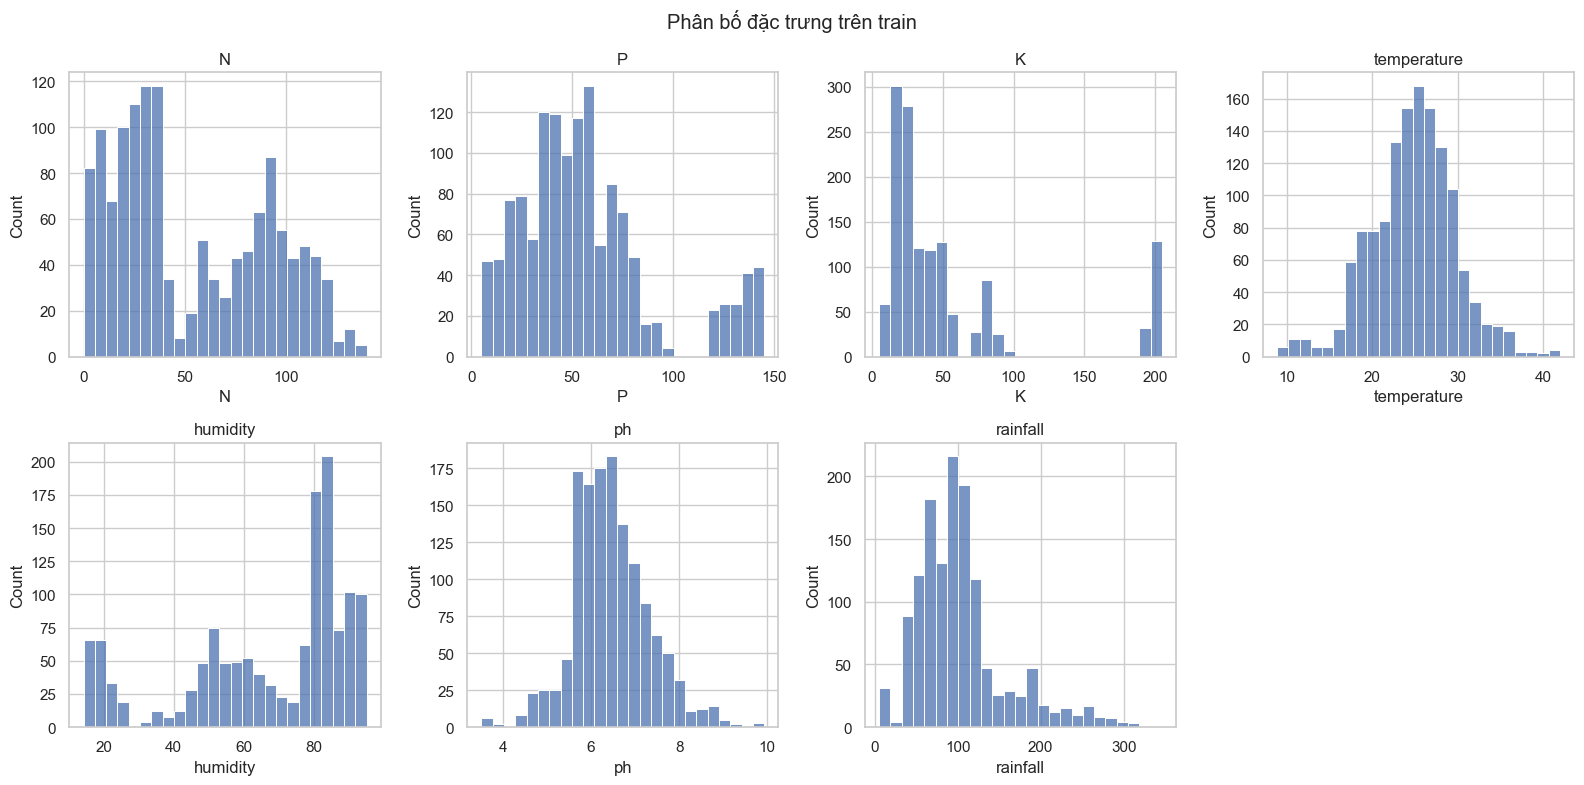

In [179]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.histplot(X_train[feature], bins=25, ax=ax)
    ax.set_title(feature)
axes.flat[-1].axis('off')
fig.suptitle('Phân bố đặc trưng trên train')
fig.tight_layout()
fig.savefig(OUT / 'feature_histograms.png', dpi=150)
plt.show()


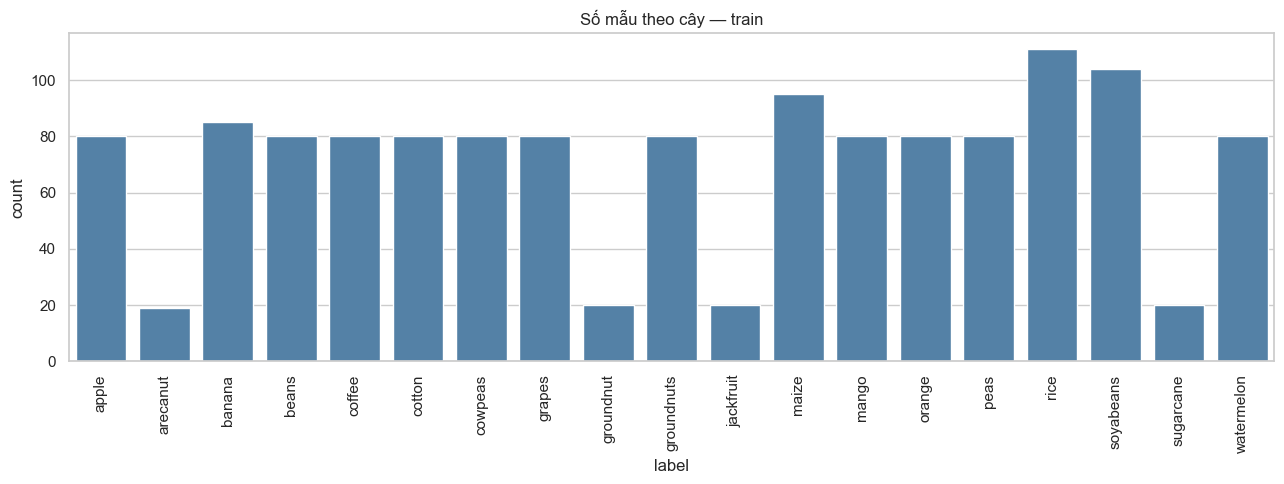

In [180]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.countplot(data=train_frame, x=TARGET, order=classes, color='steelblue', ax=ax)
ax.tick_params(axis='x', rotation=90)
ax.set_title('Số mẫu theo cây — train')
fig.tight_layout()
fig.savefig(OUT / 'class_distribution.png', dpi=150)
plt.show()


### Tương quan giữa các đặc trưng

In [181]:
correlation = X_train.corr(method='pearson')
display(correlation)
correlation.to_csv(OUT / 'tuong_quan_train.csv')


,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.293751,-0.212140,0.003870,0.246008,0.115737,0.116639
P,-0.293751,1.000000,0.803244,-0.194892,0.032380,-0.223498,-0.058344
K,-0.212140,0.803244,1.000000,-0.178832,0.220199,-0.142107,-0.050087
temperature,0.003870,-0.194892,-0.178832,1.000000,0.168114,-0.142181,-0.021226
humidity,0.246008,0.032380,0.220199,0.168114,1.000000,-0.006155,0.042851
ph,0.115737,-0.223498,-0.142107,-0.142181,-0.006155,1.000000,-0.045315
rainfall,0.116639,-0.058344,-0.050087,-0.021226,0.042851,-0.045315,1.000000


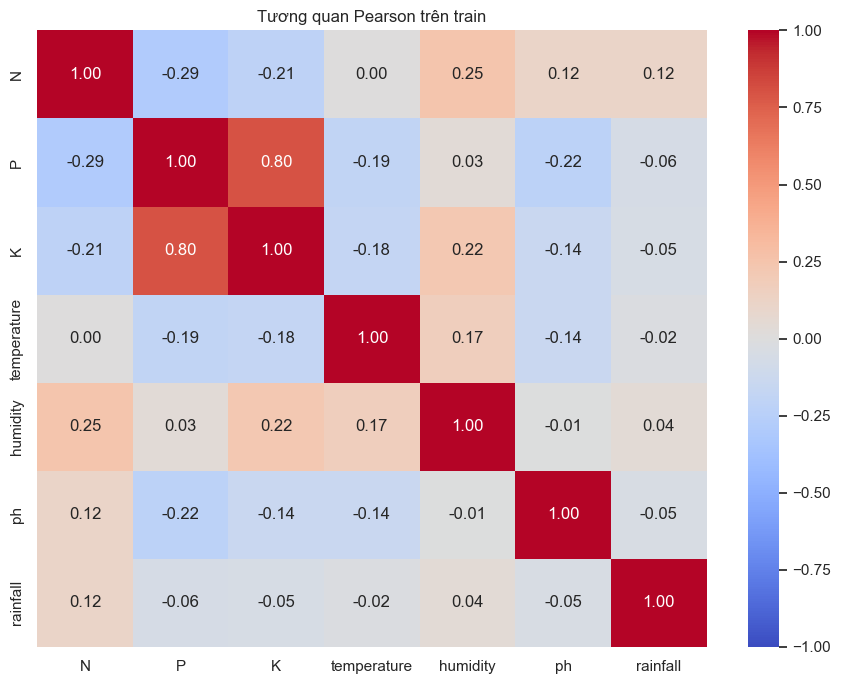

In [182]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', ax=ax)
ax.set_title('Tương quan Pearson trên train')
fig.tight_layout()
fig.savefig(OUT / 'feature_correlation.png', dpi=150)
plt.show()


Pearson mô tả quan hệ tuyến tính giữa các cột số. Xem thêm phân bố theo nhãn để đánh giá khả năng phân biệt các cây.

### Boxplot tổng quan

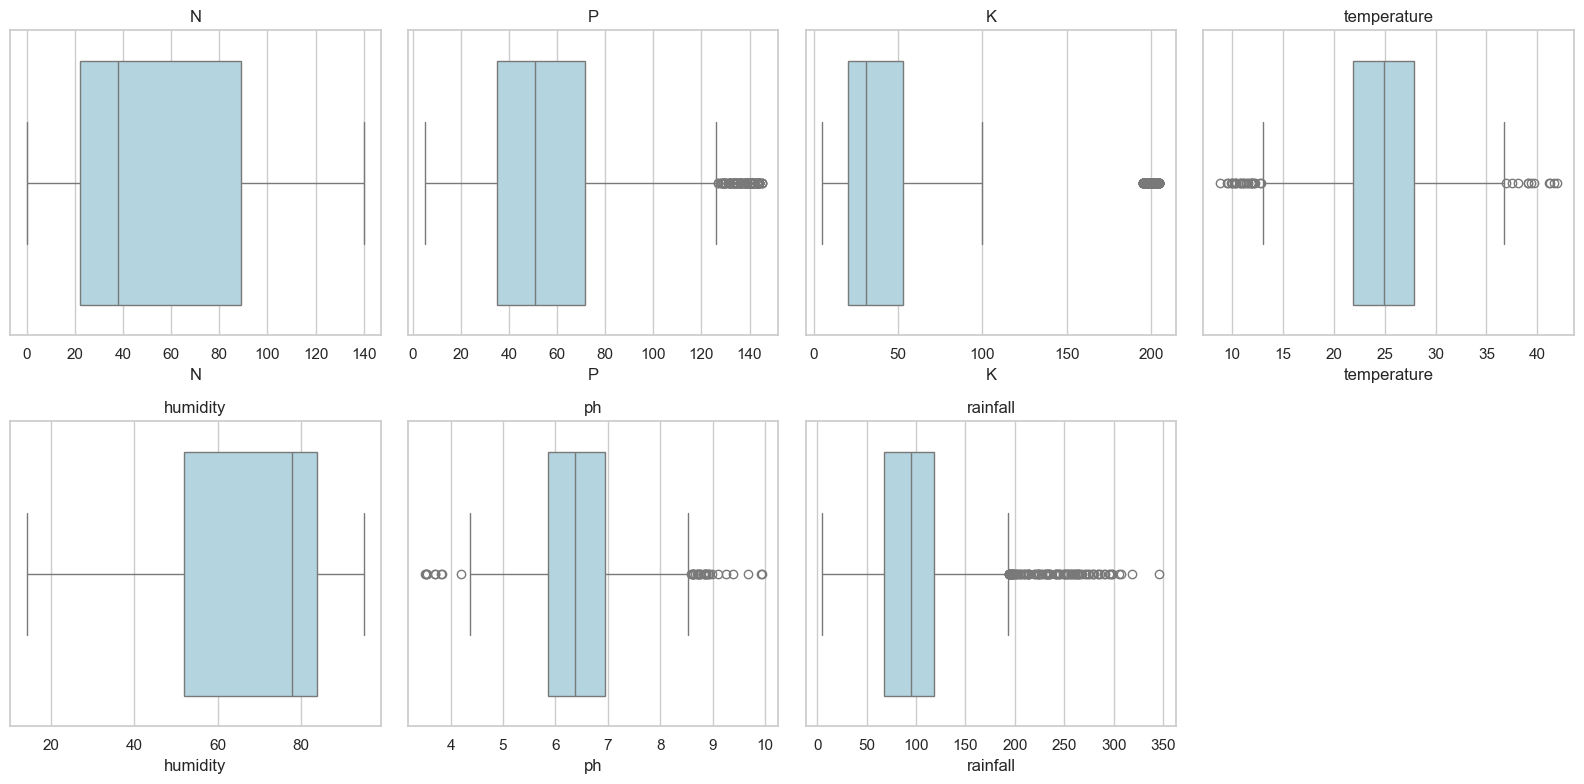

In [183]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(x=X_train[feature], ax=ax, color='lightblue')
    ax.set_title(feature)
axes.flat[-1].axis('off')
fig.tight_layout()
fig.savefig(OUT / 'feature_boxplots.png', dpi=150)
plt.show()


### Boxplot theo từng loại cây

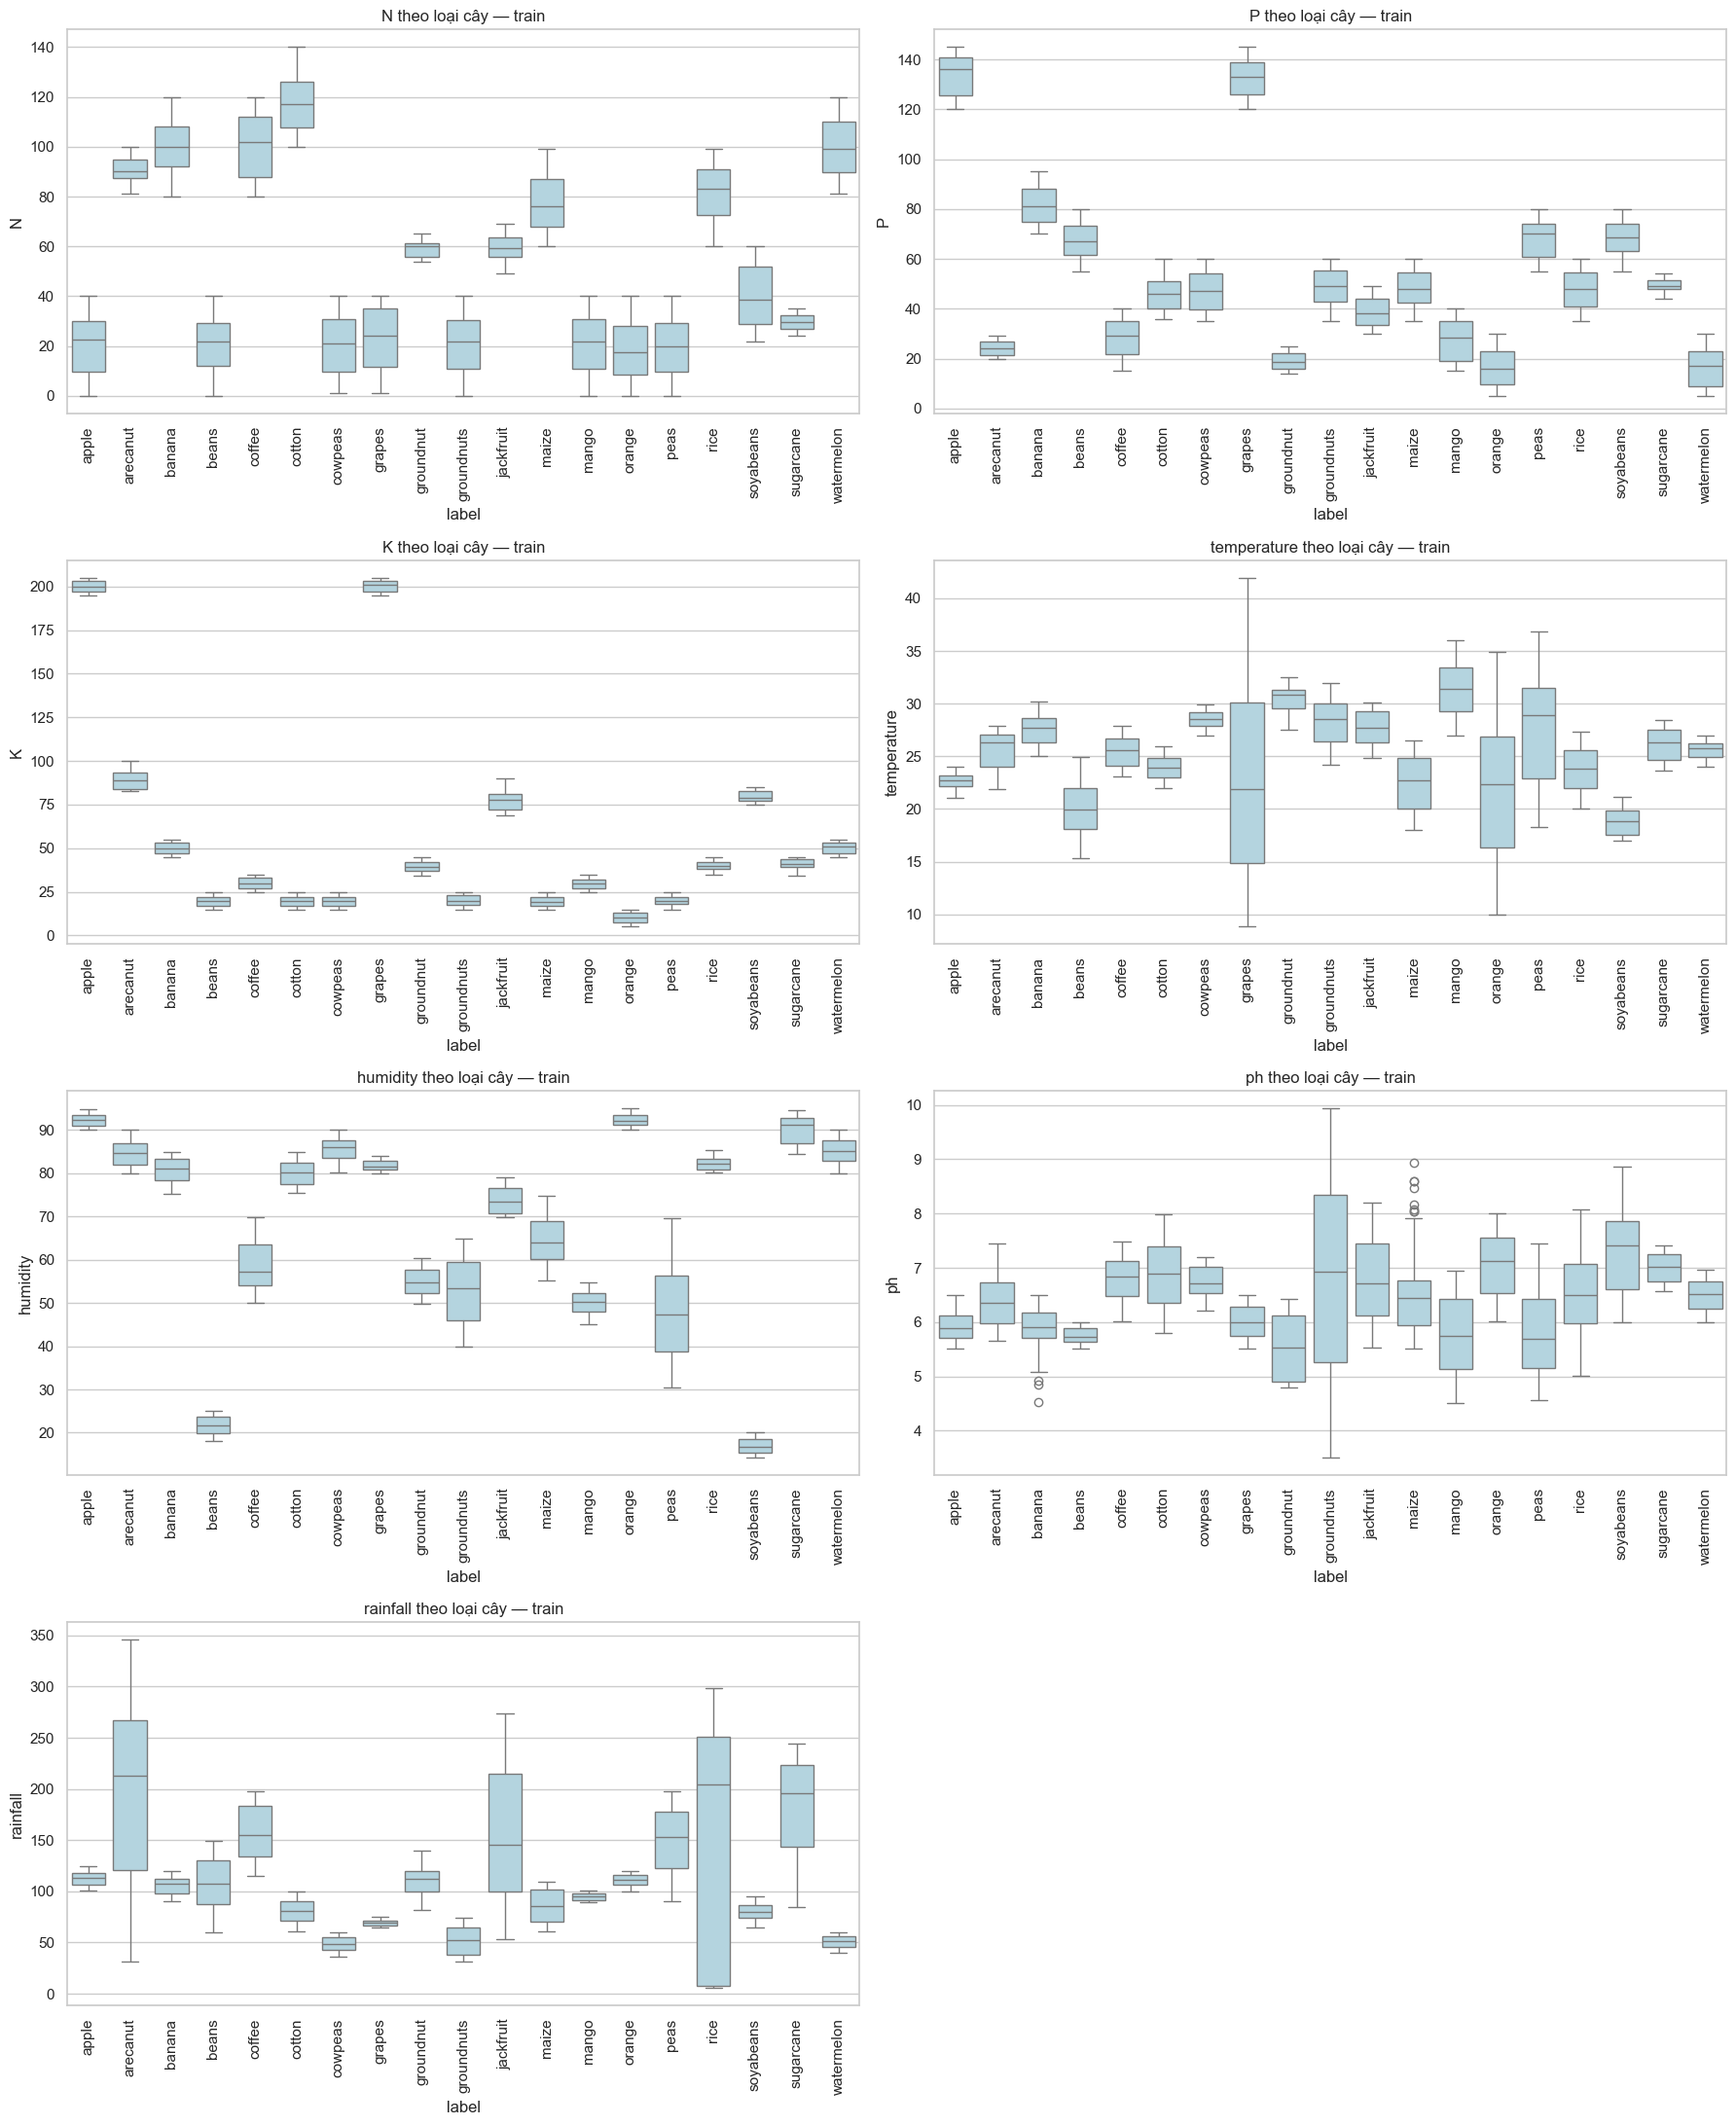

In [184]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(data=train_frame, x=TARGET, y=feature, order=classes, ax=ax, color='lightblue')
    ax.tick_params(axis='x', rotation=90)
    ax.set_title(f'{feature} theo loại cây — train')
axes.flat[-1].axis('off')
fig.tight_layout()
fig.savefig(OUT / 'features_by_crop.png', dpi=150)
plt.show()


### Kiểm tra ngoại lai bằng IQR

In [185]:
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
iqr_flags = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)


In [186]:
iqr_table = pd.DataFrame({'nguong_duoi': q1 - 1.5 * iqr, 'nguong_tren': q3 + 1.5 * iqr,
                          'so_co': iqr_flags.sum(), 'ty_le': iqr_flags.mean()})
display(iqr_table)
print('Số mẫu có ít nhất một cờ:', int(iqr_flags.any(axis=1).sum()))
print('Số mẫu loại bởi IQR: 0')
iqr_table.to_csv(OUT / 'ngoai_lai_iqr_train.csv')


,nguong_duoi,nguong_tren,so_co,ty_le
N,-78.500000,189.500000,0,0.000000
P,-20.125000,126.875000,116,0.085672
K,-29.500000,102.500000,160,0.118168
temperature,12.854158,36.835376,39,0.028804
humidity,4.047111,131.795919,0,0.000000
ph,4.237064,8.570293,39,0.028804
rainfall,-7.309742,193.498630,105,0.077548


Số mẫu có ít nhất một cờ: 316
Số mẫu loại bởi IQR: 0


IQR được tính trên train. Giữ các mẫu bị gắn cờ khi chưa có bằng chứng lỗi và xem thêm nhãn cây liên quan.

### Minh họa StandardScaler

In [187]:
illustration_scaler = StandardScaler()
X_train_scaled = pd.DataFrame(illustration_scaler.fit_transform(X_train),
                              columns=FEATURES, index=X_train.index)


In [188]:
scaling_summary = pd.DataFrame({
    'mean_truoc': X_train.mean(), 'std_truoc': X_train.std(ddof=0),
    'mean_sau': X_train_scaled.mean(), 'std_sau': X_train_scaled.std(ddof=0),
})
display(scaling_summary)
scaling_summary.to_csv(OUT / 'chuan_hoa_truoc_sau.csv')


,mean_truoc,std_truoc,mean_sau,std_sau
N,53.418759,37.681590,-8.396369e-17,1.0
P,57.042836,34.162133,-6.297277e-17,1.0
K,54.146233,56.914556,4.198185e-17,1.0
temperature,24.763986,4.935048,2.361479e-16,1.0
humidity,66.333213,23.857896,-5.037821e-16,1.0
ph,6.443158,0.875855,-7.346823e-17,1.0
rainfall,103.178633,54.261060,-1.889183e-16,1.0


Bảng trên minh họa biến đổi thang đo. Khi huấn luyện, scaler được fit riêng trong từng fold bằng Pipeline.

# Giai đoạn 2. Xây dựng và so sánh mô hình

## 6. KNN minh họa

Fit trên phần học của fold đầu, sau đó xem năm láng giềng của một mẫu validation.

In [189]:
knn_example = Pipeline([
    ('scale', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='uniform', algorithm='brute')),
])
print(knn_example)


Pipeline(steps=[('scale', StandardScaler()),
                ('knn',
                 KNeighborsClassifier(algorithm='brute', metric='euclidean'))])


In [190]:
fit_ids, val_ids = cv_splits[0]
knn_example.fit(X_train.iloc[fit_ids], y_train.iloc[fit_ids])
query = X_train.iloc[val_ids[:1]]
display(query)
print('Nhãn thật:', y_train.iloc[val_ids[0]])
print('Dự đoán:', knn_example.predict(query)[0])


,N,P,K,temperature,humidity,ph,rainfall
sample_id,,,,,,,
0,90.0,42.0,43.0,20.879744,82.002744,6.502985,202.935536


Nhãn thật: rice
Dự đoán: rice


In [191]:
query_scaled = knn_example.named_steps['scale'].transform(query)
distances, local_ids = knn_example.named_steps['knn'].kneighbors(query_scaled)
neighbors = X_train.iloc[fit_ids].iloc[local_ids[0]].copy()
neighbor_labels = y_train.iloc[fit_ids].iloc[local_ids[0]].to_numpy()
neighbors[TARGET] = neighbor_labels
neighbors['distance_scaled'] = distances[0]
display(neighbors)


,N,P,K,temperature,humidity,ph,rainfall,label,distance_scaled
sample_id,,,,,,,,,
20,89.0,45.0,36.0,21.325042,80.474764,6.442475,185.497473,rice,0.381915
31,92.0,35.0,40.0,22.179319,80.331272,6.357389,200.088279,rice,0.386452
29,84.0,51.0,35.0,22.301574,80.644165,6.043305,197.979121,rice,0.688876
48,79.0,43.0,39.0,21.666283,80.709606,7.062779,210.814209,rice,0.733084
51,76.0,60.0,39.0,20.045414,80.347756,6.766240,208.581016,rice,0.746949


In [192]:
votes = pd.Series(neighbor_labels).value_counts().rename('so_phieu').to_frame()
votes['ty_le_phieu'] = votes['so_phieu'] / 5
display(votes)


,so_phieu,ty_le_phieu
rice,5,1.0


In [193]:
probability = knn_example.predict_proba(query)[0]
manual_probability = np.array([(neighbor_labels == label).mean() for label in knn_example.classes_])
np.testing.assert_allclose(probability, manual_probability)
assert len(probability) == len(classes) and np.isclose(probability.sum(), 1)
display(pd.Series(probability, index=knn_example.classes_, name='xac_suat').sort_values(ascending=False).head(5))
print('Đã đối chiếu phiếu thủ công. Một mẫu chưa đủ để đánh giá chất lượng mô hình.')


rice        1.0
arecanut    0.0
apple       0.0
banana      0.0
beans       0.0
Name: xac_suat, dtype: float64

Đã đối chiếu phiếu thủ công. Một mẫu chưa đủ để đánh giá chất lượng mô hình.


Bảng láng giềng và tỷ lệ phiếu giải thích một dự đoán. Điểm của một mẫu riêng lẻ chưa thể hiện chất lượng toàn bộ mô hình.

## 7. Huấn luyện và chọn cấu hình KNN

### Lưu kết quả từng mô hình

In [194]:
searches = {}


In [195]:
def guard_training(name):
    if (OUT / 'comparison.csv').exists() or (OUT / 'test_predictions.csv').exists():
        raise RuntimeError('Test đã được đánh giá. Chỉ đọc kết quả, không tuning theo test.')
    if (OUT / f'{name}_search.joblib').exists():
        raise FileExistsError(f'Đã có kết quả {name}; nạp lại hoặc giữ riêng lần thí nghiệm mới.')


In [196]:
def save_search(name, search):
    searches[name] = search
    joblib.dump(search, OUT / f'{name}_search.joblib')
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'{name}_cv_raw.csv', index=False)
    print(name, '| Tham số:', search.best_params_, '| CV F1 macro:', search.best_score_)


### Nạp lại phiên đang làm nếu cần

Lần chạy mới giữ `RESTORE_SEARCHES=False`. Khi tiếp tục đúng phiên cũ, đặt thành `True` và bỏ qua các ô fit đã có kết quả.

In [197]:
RESTORE_SEARCHES = False
if RESTORE_SEARCHES:
    for name in list(MODEL_ROLES):
        saved = OUT / f'{name}_search.joblib'
        if saved.is_file():
            searches[name] = joblib.load(saved)
    if 'KNN' in searches:
        knn_search = searches['KNN']
    print('Đã nạp:', list(searches))


### Khai báo Pipeline và lưới tham số

In [198]:
knn_pipeline = Pipeline([
    ('scale', 'passthrough'),
    ('knn', KNeighborsClassifier(algorithm='brute', n_jobs=1)),
])


In [199]:
common_grid = {
    'scale': ['passthrough', StandardScaler(), MinMaxScaler()],
    'knn__n_neighbors': K_VALUES,
    'knn__weights': ['uniform', 'distance'],
}
knn_grid = [
    {**common_grid, 'knn__metric': ['euclidean', 'manhattan']},
    {**common_grid, 'knn__metric': ['minkowski'], 'knn__p': [3]},
]
print('Số cấu hình:', len(ParameterGrid(knn_grid)))


Số cấu hình: 162


In [200]:
if 'KNN' in searches:
    knn_search = searches['KNN']  # Giữ tìm kiếm đã nạp khi khôi phục phiên.
else:
    knn_search = GridSearchCV(
        knn_pipeline, knn_grid, scoring=SCORING, refit='f1_macro',
        cv=cv_splits, n_jobs=N_JOBS, return_train_score=True, error_score='raise', verbose=1,
    )


### Fit KNN trên train

In [201]:
guard_training('KNN')
with threadpool_limits(limits=1):
    knn_search.fit(X_train, y_train)
save_search('KNN', knn_search)


Fitting 5 folds for each of 162 candidates, totalling 810 fits
KNN | Tham số: {'knn__metric': 'euclidean', 'knn__n_neighbors': 5, 'knn__weights': 'uniform', 'scale': MinMaxScaler()} | CV F1 macro: 0.9956561952866757


## 8. Đọc kết quả KNN

### Điểm CV của các cấu hình

In [202]:
def scaler_name(value):
    if isinstance(value, str):
        return 'none'
    return 'standard' if isinstance(value, StandardScaler) else 'minmax'


In [203]:
result = knn_search.cv_results_
rows = []
for i, params in enumerate(result['params']):
    rows.append({
        'K': params['knn__n_neighbors'], 'scale': scaler_name(params['scale']),
        'metric': 'minkowski_p3' if params['knn__metric'] == 'minkowski' else params['knn__metric'],
        'weights': params['knn__weights'],
        'cv_accuracy': result['mean_test_accuracy'][i],
        'cv_f1_macro': result['mean_test_f1_macro'][i], 'cv_sd': result['std_test_f1_macro'][i],
        'train_f1_macro': result['mean_train_f1_macro'][i],
    })


In [204]:
knn_results = pd.DataFrame(rows)
display(knn_results.sort_values('cv_f1_macro', ascending=False).head(10))
knn_results.to_csv(OUT / 'knn_cv.csv', index=False)


,K,scale,metric,weights,cv_accuracy,cv_f1_macro,cv_sd,train_f1_macro
17,5,minmax,euclidean,distance,0.996307,0.995656,0.004619,1.000000
14,5,minmax,euclidean,uniform,0.996307,0.995656,0.004619,0.996041
56,1,minmax,manhattan,uniform,0.995569,0.995067,0.004196,1.000000
59,1,minmax,manhattan,distance,0.995569,0.995067,0.004196,1.000000
29,9,minmax,euclidean,distance,0.995569,0.995016,0.005770,1.000000
11,3,minmax,euclidean,distance,0.995569,0.995016,0.005770,1.000000
68,5,minmax,manhattan,uniform,0.995569,0.995016,0.005770,0.996133
71,5,minmax,manhattan,distance,0.995569,0.995016,0.005770,1.000000
8,3,minmax,euclidean,uniform,0.995569,0.995016,0.005770,0.998368
77,7,minmax,manhattan,distance,0.995569,0.995016,0.005770,1.000000


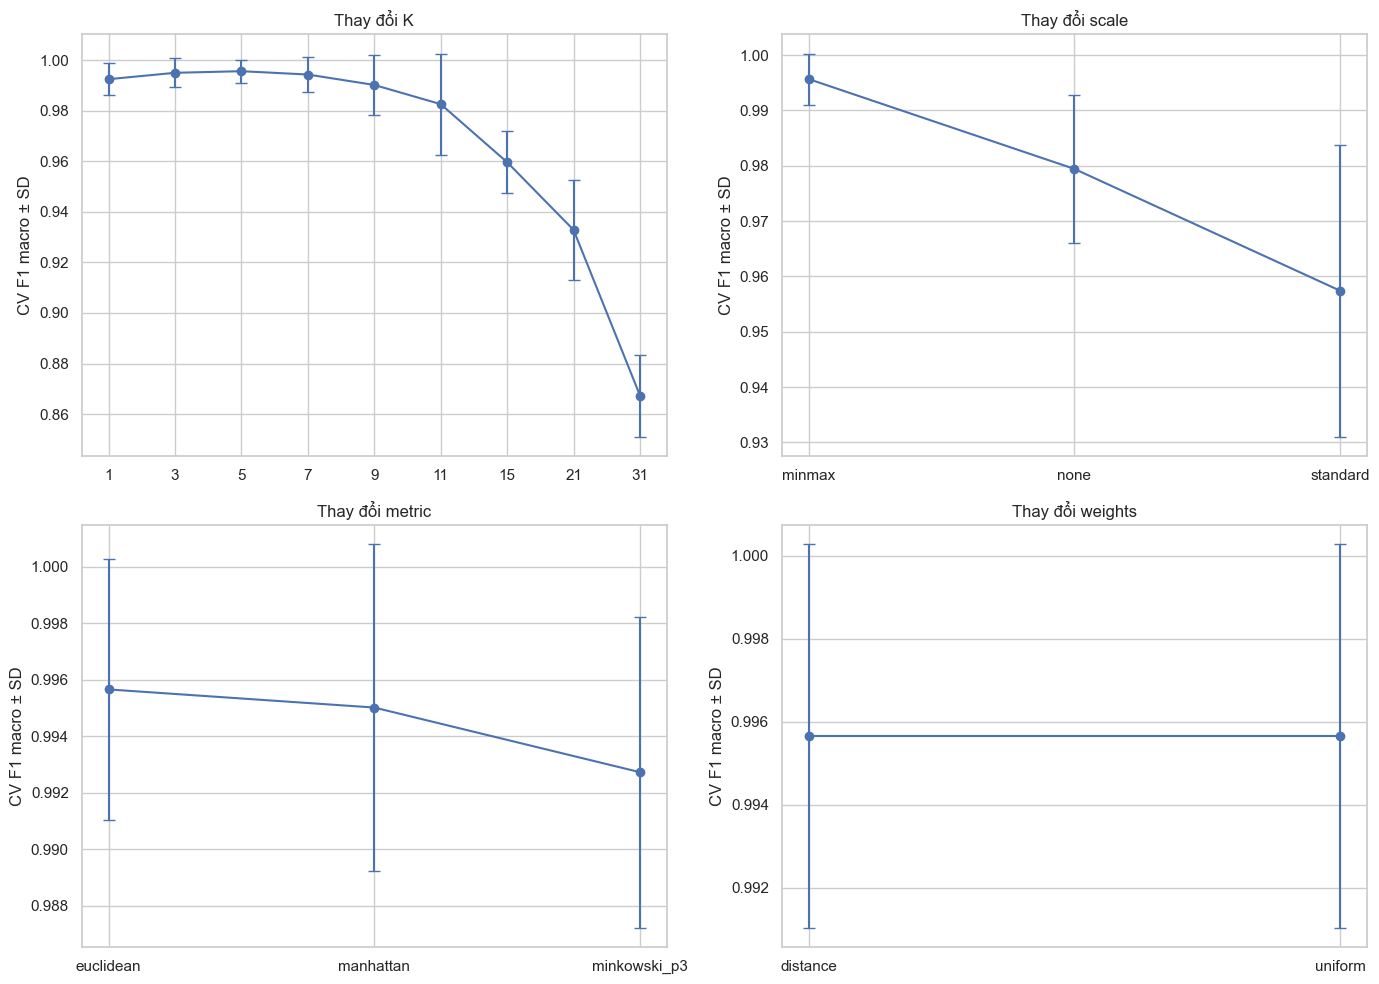

In [205]:
best = knn_results.iloc[knn_search.best_index_]
factors = ['K', 'scale', 'metric', 'weights']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, factor in zip(axes.flat, factors):
    mask = pd.Series(True, index=knn_results.index)
    for other in factors:
        if other != factor:
            mask &= knn_results[other].eq(best[other])
    part = knn_results.loc[mask].sort_values(factor)
    positions = np.arange(len(part))
    ax.errorbar(positions, part['cv_f1_macro'], yerr=part['cv_sd'], marker='o', capsize=4)
    ax.set_xticks(positions, part[factor].astype(str))
    ax.set_title(f'Thay đổi {factor}')
    ax.set_ylabel('CV F1 macro ± SD')
fig.tight_layout()
fig.savefig(OUT / 'knn_factors.png', dpi=150)
plt.show()


Mỗi biểu đồ thay một yếu tố và giữ các yếu tố còn lại theo cấu hình đã chọn. Đọc điểm trung bình cùng thanh sai số.

### So sánh train và validation theo fold

In [206]:
i = knn_search.best_index_
knn_folds = pd.DataFrame({
    'fold': range(1, N_SPLITS + 1),
    'train_f1_macro': [result[f'split{j}_train_f1_macro'][i] for j in range(N_SPLITS)],
    'validation_f1_macro': [result[f'split{j}_test_f1_macro'][i] for j in range(N_SPLITS)],
})
knn_folds['gap'] = knn_folds['train_f1_macro'] - knn_folds['validation_f1_macro']
display(knn_folds)
knn_folds.to_csv(OUT / 'knn_selected_folds.csv', index=False)


,fold,train_f1_macro,validation_f1_macro,gap
0,1,0.995493,0.993980,0.001512
1,2,0.994033,0.996707,-0.002675
2,3,0.998421,0.987594,0.010827
3,4,0.996131,1.000000,-0.003869
4,5,0.996126,1.000000,-0.003874


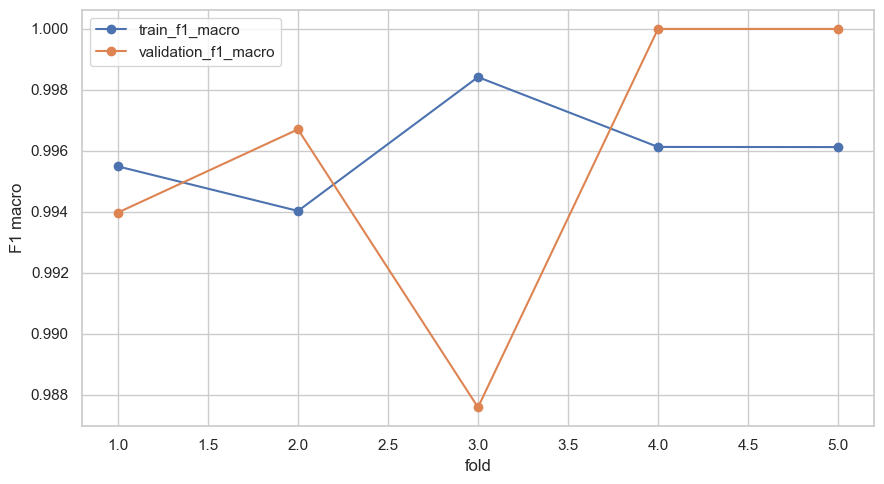

In [207]:
ax = knn_folds.plot(x='fold', y=['train_f1_macro', 'validation_f1_macro'], marker='o', figsize=(9, 5))
ax.set_ylabel('F1 macro')
ax.figure.tight_layout()
ax.figure.savefig(OUT / 'knn_train_cv.png', dpi=150)
plt.show()


KNN có thể đạt train F1 bằng 1 khi dự đoán lại mẫu học bằng trọng số khoảng cách. Cần xem điểm validation và các lỗi cụ thể.

## 9. Baseline và các mô hình so sánh

### Gaussian Naive Bayes

In [208]:
nb_model = Pipeline([('scale', StandardScaler()), ('model', GaussianNB())])


In [209]:
nb_grid = {'model__var_smoothing': [1e-11, 1e-9, 1e-7]}


In [210]:
nb_search = GridSearchCV(
    nb_model, nb_grid, scoring=SCORING, refit='f1_macro', cv=cv_splits,
    n_jobs=N_JOBS, return_train_score=True, error_score='raise',
)


In [211]:
guard_training('GaussianNB')
with threadpool_limits(limits=1):
    nb_search.fit(X_train, y_train)
save_search('GaussianNB', nb_search)


GaussianNB | Tham số: {'model__var_smoothing': 1e-11} | CV F1 macro: 0.9993965257123152


### Decision Tree

In [212]:
tree_model = DecisionTreeClassifier(random_state=SEED)


In [213]:
tree_grid = {'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 3]}


In [214]:
tree_search = GridSearchCV(
    tree_model, tree_grid, scoring=SCORING, refit='f1_macro', cv=cv_splits,
    n_jobs=N_JOBS, return_train_score=True, error_score='raise',
)


In [215]:
guard_training('DecisionTree')
tree_search.fit(X_train, y_train)
save_search('DecisionTree', tree_search)


DecisionTree | Tham số: {'max_depth': None, 'min_samples_leaf': 1} | CV F1 macro: 0.9841651964788716


### Random Forest

In [216]:
forest_model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)


In [217]:
forest_grid = {'max_depth': [None, 10], 'min_samples_leaf': [1, 2]}


In [218]:
forest_search = GridSearchCV(
    forest_model, forest_grid, scoring=SCORING, refit='f1_macro', cv=cv_splits,
    n_jobs=N_JOBS, return_train_score=True, error_score='raise',
)


In [219]:
guard_training('RandomForest')
with threadpool_limits(limits=1):
    forest_search.fit(X_train, y_train)
save_search('RandomForest', forest_search)


RandomForest | Tham số: {'max_depth': None, 'min_samples_leaf': 1} | CV F1 macro: 0.998177261335156


# Giai đoạn 3. Cải tiến và lựa chọn bằng CV

## 10. So sánh cấu hình và lựa chọn đặc trưng

So sánh bốn biến thể trên cùng năm fold. Các bước chọn đặc trưng được fit trong Pipeline.

In [220]:
ABLATION_NAMES = ['start_7', 'tuned_7', 'start_5', 'tuned_5']
mi_score = partial(mutual_info_classif, random_state=SEED)
ablation_pipeline = Pipeline([
    ('scale', 'passthrough'), ('select', 'passthrough'),
    ('knn', KNeighborsClassifier(algorithm='brute', n_jobs=1)),
])


In [221]:
initial_model = clone(knn_example)
tuned_model = clone(searches['KNN'].best_estimator_)


In [222]:
ablation_grid = []
for name in ABLATION_NAMES:
    base = initial_model if name.startswith('start') else tuned_model
    scaler = base.named_steps['scale']
    scaler = scaler if isinstance(scaler, str) else clone(scaler)
    selector = SelectKBest(mi_score, k=SELECTED_FEATURE_COUNT) if name.endswith('_5') else 'passthrough'
    ablation_grid.append({'scale': [scaler], 'select': [selector],
                          'knn': [clone(base.named_steps['knn'])]})
print('Số biến thể:', len(ParameterGrid(ablation_grid)))


Số biến thể: 4


In [223]:
if 'KNN_final' in searches:
    final_search = searches['KNN_final']
else:
    final_search = GridSearchCV(
        ablation_pipeline, ablation_grid, scoring=SCORING, refit='f1_macro',
        cv=cv_splits, n_jobs=N_JOBS, return_train_score=True, error_score='raise',
    )


### Fit bốn biến thể KNN

In [224]:
guard_training('KNN_final')
with threadpool_limits(limits=1):
    final_search.fit(X_train, y_train)
save_search('KNN_final', final_search)


KNN_final | Tham số: {'knn': KNeighborsClassifier(algorithm='brute', metric='euclidean', n_jobs=1), 'scale': MinMaxScaler(), 'select': 'passthrough'} | CV F1 macro: 0.9956561952866757


In [225]:
ablation_result = final_search.cv_results_
ablation_summary = pd.DataFrame({
    'variant': ABLATION_NAMES,
    'so_dac_trung': [7, 7, SELECTED_FEATURE_COUNT, SELECTED_FEATURE_COUNT],
    'train_f1_macro': ablation_result['mean_train_f1_macro'],
    'train_f1_sd': ablation_result['std_train_f1_macro'],
    'cv_accuracy': ablation_result['mean_test_accuracy'],
    'cv_accuracy_sd': ablation_result['std_test_accuracy'],
    'cv_f1_macro': ablation_result['mean_test_f1_macro'],
    'cv_f1_sd': ablation_result['std_test_f1_macro'],
    'fit_seconds': ablation_result['mean_fit_time'],
    'score_seconds': ablation_result['mean_score_time'],
})
ablation_summary['gap'] = ablation_summary['train_f1_macro'] - ablation_summary['cv_f1_macro']


In [226]:
display(ablation_summary)
ablation_summary.to_csv(OUT / 'knn_ablation.csv', index=False)
print('Biến thể được chọn bằng CV:', ABLATION_NAMES[final_search.best_index_])


,variant,so_dac_trung,train_f1_macro,train_f1_sd,cv_accuracy,cv_accuracy_sd,cv_f1_macro,cv_f1_sd,fit_seconds,score_seconds,gap
0,start_7,7,0.980870,0.006396,0.980798,0.010278,0.957418,0.026359,0.002436,0.005334,0.023452
1,tuned_7,7,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,0.002663,0.004438,0.000384
2,start_5,5,0.995496,0.001451,0.994834,0.005005,0.993653,0.005418,0.078167,0.005642,0.001843
3,tuned_5,5,0.996519,0.001799,0.994834,0.004428,0.993455,0.005796,0.073420,0.005212,0.003064


Biến thể được chọn bằng CV: tuned_7


In [227]:
scores = ablation_summary.set_index('variant')['cv_f1_macro']
changes = [('Tối ưu cấu hình, giữ 7 đặc trưng', 'start_7', 'tuned_7'),
           ('Chọn đặc trưng, giữ cấu hình ban đầu', 'start_7', 'start_5'),
           ('Chọn đặc trưng, giữ cấu hình tối ưu', 'tuned_7', 'tuned_5')]
ablation_effects = pd.DataFrame([
    {'thay_doi': title, 'truoc': before, 'sau': after,
     'chenh_f1_diem_phan_tram': 100 * (scores[after] - scores[before])}
    for title, before, after in changes
])


In [228]:
display(ablation_effects)
ablation_effects.to_csv(OUT / 'knn_ablation_effects.csv', index=False, encoding='utf-8-sig')


,thay_doi,truoc,sau,chenh_f1_diem_phan_tram
0,"Tối ưu cấu hình, giữ 7 đặc trưng",start_7,tuned_7,3.823793
1,"Chọn đặc trưng, giữ cấu hình ban đầu",start_7,start_5,3.623468
2,"Chọn đặc trưng, giữ cấu hình tối ưu",tuned_7,tuned_5,-0.220111


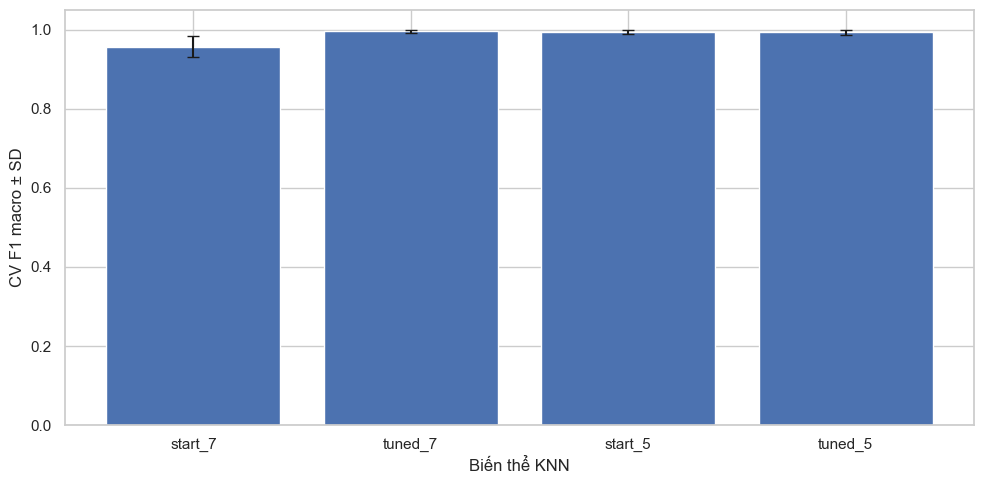

In [229]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(ablation_summary['variant'], ablation_summary['cv_f1_macro'],
       yerr=ablation_summary['cv_f1_sd'], capsize=4)
ax.set_xlabel('Biến thể KNN')
ax.set_ylabel('CV F1 macro ± SD')
ax.set_ylim(0, 1.05)
fig.tight_layout()
fig.savefig(OUT / 'knn_ablation.png', dpi=150)
plt.show()


Đọc chênh lệch của từng thay đổi trong bảng trước–sau. Chọn biến thể theo CV F1 macro.

### Mutual information trên train

In [230]:
mi_table = pd.DataFrame({'dac_trung': FEATURES, 'mutual_information': mi_score(X_train, y_train)})
mi_table = mi_table.sort_values('mutual_information', ascending=False)
display(mi_table)
mi_table.to_csv(OUT / 'mutual_information_train.csv', index=False, encoding='utf-8-sig')


,dac_trung,mutual_information
2,K,1.732615
4,humidity,1.699439
6,rainfall,1.429131
1,P,1.386368
0,N,1.091480
3,temperature,0.999795
5,ph,0.637476


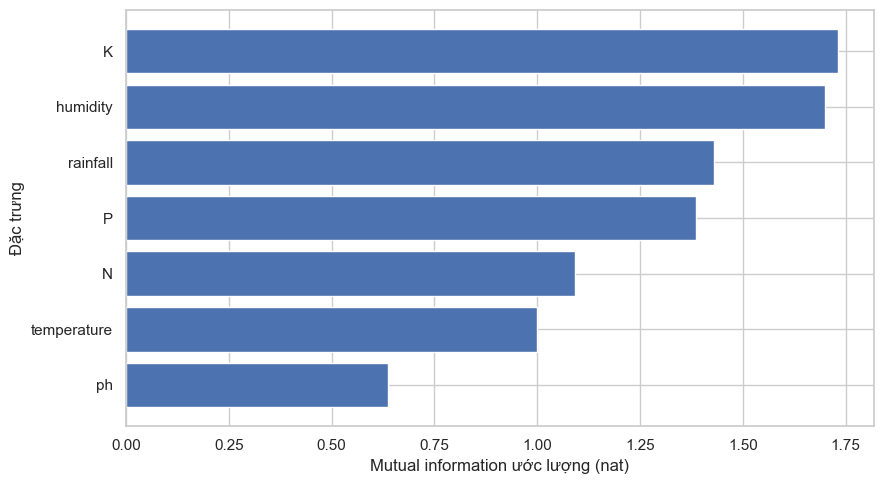

In [231]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(mi_table['dac_trung'][::-1], mi_table['mutual_information'][::-1])
ax.set_xlabel('Mutual information ước lượng (nat)')
ax.set_ylabel('Đặc trưng')
fig.tight_layout()
fig.savefig(OUT / 'mutual_information_train.png', dpi=150)
plt.show()


Điểm này mô tả quan hệ của từng đặc trưng với nhãn. Bảng ablation cho biết tác động khi chọn nhiều đặc trưng cùng nhau.

## 11. Learning curve và cách tìm láng giềng

### Learning curve

In [232]:
from sklearn.model_selection import learning_curve

learning_scorer = make_scorer(
    f1_score, labels=classes, average='macro', pos_label=None, zero_division=0,
)
if (OUT / 'comparison.csv').exists() or (OUT / 'test_predictions.csv').exists():
    raise RuntimeError('Test đã được đánh giá; đọc bảng learning curve đã lưu của lần chạy này.')


In [233]:
with threadpool_limits(limits=1):
    sizes, train_scores, val_scores = learning_curve(
        clone(final_search.best_estimator_), X_train, y_train, cv=cv_splits,
        train_sizes=[0.25, 0.50, 0.75, 1.0], scoring=learning_scorer,
        shuffle=True, random_state=SEED, n_jobs=N_JOBS, error_score='raise',
    )


In [234]:
learning_table = pd.DataFrame({'so_mau': sizes,
    'train': train_scores.mean(axis=1), 'train_sd': train_scores.std(axis=1),
    'validation': val_scores.mean(axis=1), 'validation_sd': val_scores.std(axis=1)})
display(learning_table)
learning_table.to_csv(OUT / 'knn_learning_curve.csv', index=False)


,so_mau,train,train_sd,validation,validation_sd
0,270,0.877685,0.055533,0.857951,0.052718
1,541,0.961656,0.038368,0.962043,0.036340
2,812,0.994588,0.002633,0.990383,0.009066
3,1083,0.996041,0.001415,0.995656,0.004619


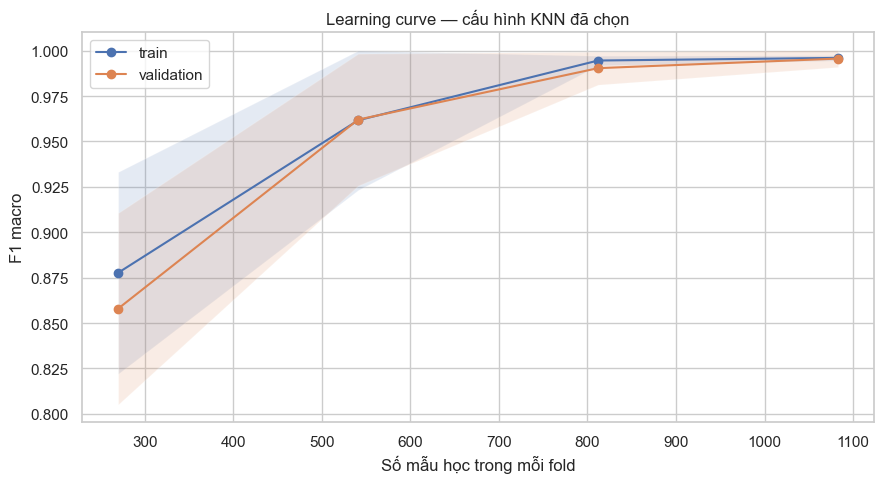

In [235]:
fig, ax = plt.subplots(figsize=(9, 5))
for prefix in ['train', 'validation']:
    mean, sd = learning_table[prefix].to_numpy(), learning_table[prefix + '_sd'].to_numpy()
    ax.plot(sizes, mean, 'o-', label=prefix)
    ax.fill_between(sizes, mean - sd, mean + sd, alpha=0.15)
ax.set_xlabel('Số mẫu học trong mỗi fold')
ax.set_ylabel('F1 macro')
ax.set_title('Learning curve — cấu hình KNN đã chọn')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'knn_learning_curve.png', dpi=150)
plt.show()


Trục ngang là số mẫu học trong mỗi fold. Đọc điểm validation, khoảng cách với train và độ rộng vùng sai số.

### Brute, KD-Tree và Ball-Tree

In [236]:
from time import perf_counter

if (OUT / 'comparison.csv').exists() or (OUT / 'test_predictions.csv').exists():
    raise RuntimeError('Đã mở test; giữ kết quả hiện có.')
fit_ids, val_ids = cv_splits[0]
X_fit, y_fit = X_train.iloc[fit_ids], y_train.iloc[fit_ids]
X_query = X_train.iloc[val_ids]
benchmark_rows, backend_distances, backend_labels = [], {}, {}
rng = np.random.default_rng(SEED)


In [237]:
with threadpool_limits(limits=1):
    for repeat in range(5):
        for backend in rng.permutation(['brute', 'kd_tree', 'ball_tree']):
            candidate = clone(knn_search.best_estimator_).set_params(knn__algorithm=str(backend))
            start = perf_counter()
            candidate.fit(X_fit, y_fit)
            fit_ms = 1000 * (perf_counter() - start)
            scaler = candidate.named_steps['scale']
            transformed = X_query if isinstance(scaler, str) else scaler.transform(X_query)
            neighbor_model = candidate.named_steps['knn']
            neighbor_model.kneighbors(transformed[:1])
            start = perf_counter()
            distances, _ = neighbor_model.kneighbors(transformed)
            query_ms = 1000 * (perf_counter() - start)
            benchmark_rows.append({'backend': str(backend), 'repeat': repeat + 1,
                                   'fit_ms': fit_ms, 'query_batch_ms': query_ms})
            backend_distances[str(backend)] = distances
            backend_labels[str(backend)] = candidate.predict(X_query)


In [238]:
benchmark = pd.DataFrame(benchmark_rows)
benchmark.to_csv(OUT / 'neighbors_benchmark_raw.csv', index=False)
benchmark_summary = benchmark.groupby('backend')[['fit_ms', 'query_batch_ms']].median()
benchmark_summary['query_ms_per_sample'] = benchmark_summary['query_batch_ms'] / len(X_query)
benchmark_summary['label_agreement_with_brute'] = [
    np.mean(backend_labels[name] == backend_labels['brute']) for name in benchmark_summary.index]
benchmark_summary['distances_equal_to_brute'] = [
    np.allclose(backend_distances[name], backend_distances['brute']) for name in benchmark_summary.index]


In [239]:
display(benchmark_summary)
benchmark_summary.to_csv(OUT / 'neighbors_benchmark.csv')


,fit_ms,query_batch_ms,query_ms_per_sample,label_agreement_with_brute,distances_equal_to_brute
backend,,,,,
ball_tree,2.3342,1.6009,0.005907,1.0,True
brute,1.8827,1.1378,0.004199,1.0,True
kd_tree,2.5355,1.0683,0.003942,1.0,True


Thời gian được đo trên một batch validation. Đối chiếu cả thời gian fit, truy vấn và mức khớp nhãn giữa các backend.

## 12. Tổng hợp CV và chốt mô hình

In [240]:
required_models = list(MODEL_ROLES)
assert all(name in searches for name in required_models), 'Cần hoàn thành hoặc nạp lại bốn mô hình và biến thể KNN cuối.'


In [241]:
cv_rows = []
for name in required_models:
    search = searches[name]
    i, result = search.best_index_, search.cv_results_
    cv_rows.append({'model': name, 'vai_tro': MODEL_ROLES[name],
        'train_f1_macro': result['mean_train_f1_macro'][i],
        'train_f1_sd': result['std_train_f1_macro'][i],
        'cv_accuracy': result['mean_test_accuracy'][i], 'cv_accuracy_sd': result['std_test_accuracy'][i],
        'cv_f1_macro': result['mean_test_f1_macro'][i], 'cv_f1_sd': result['std_test_f1_macro'][i],
        'best_params': str(search.best_params_), 'candidates': len(result['params'])})


In [242]:
cv_summary = pd.DataFrame(cv_rows)
cv_summary['gap'] = cv_summary['train_f1_macro'] - cv_summary['cv_f1_macro']
display(cv_summary)
cv_summary.to_csv(OUT / 'cv_summary.csv', index=False)


,model,vai_tro,train_f1_macro,train_f1_sd,cv_accuracy,cv_accuracy_sd,cv_f1_macro,cv_f1_sd,best_params,candidates,gap
0,KNN,Mô hình chính,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",162,0.000384
1,GaussianNB,Baseline,0.999395,0.000303,0.999262,0.001476,0.999397,0.001207,{'model__var_smoothing': 1e-11},3,-0.000002
2,DecisionTree,So sánh,1.000000,0.000000,0.991141,0.005993,0.984165,0.011647,"{'max_depth': None, 'min_samples_leaf': 1}",6,0.015835
3,RandomForest,So sánh,1.000000,0.000000,0.999262,0.001476,0.998177,0.003645,"{'max_depth': None, 'min_samples_leaf': 1}",4,0.001823
4,KNN_final,Biến thể KNN chọn bằng CV,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,{'knn': KNeighborsClassifier(algorithm='brute'...,4,0.000384


In [243]:
final_variant = ABLATION_NAMES[final_search.best_index_]
final_pipeline = final_search.best_estimator_
selector = final_pipeline.named_steps['select']
selected_features = FEATURES.copy() if isinstance(selector, str) else list(np.array(FEATURES)[selector.get_support()])


In [244]:
selection = {
    'best_model_by_cv': cv_summary.sort_values('cv_f1_macro', ascending=False).iloc[0]['model'],
    'demo_model': 'KNN_final', 'criterion': 'CV F1 macro', 'final_variant': final_variant,
    'selected_features': selected_features, 'knn_params': str(searches['KNN'].best_params_),
    'final_params': {'scale': final_pipeline.named_steps['scale'] if isinstance(final_pipeline.named_steps['scale'], str)
                     else type(final_pipeline.named_steps['scale']).__name__,
                     'feature_count': len(selected_features),
                     'knn': final_pipeline.named_steps['knn'].get_params(deep=False)},
}


In [245]:
selection_path = OUT / 'selection.json'
if selection_path.exists():
    if json.loads(selection_path.read_text(encoding='utf-8')) != selection:
        raise ValueError('Lựa chọn khác hồ sơ đã lưu. Kiểm tra phiên bản thực nghiệm.')
else:
    selection_path.write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('Biến thể KNN dùng demo:', final_variant)
print('Đặc trưng sử dụng:', selected_features)
print('Mô hình điểm CV cao nhất:', selection['best_model_by_cv'])


Biến thể KNN dùng demo: tuned_7
Đặc trưng sử dụng: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Mô hình điểm CV cao nhất: GaussianNB


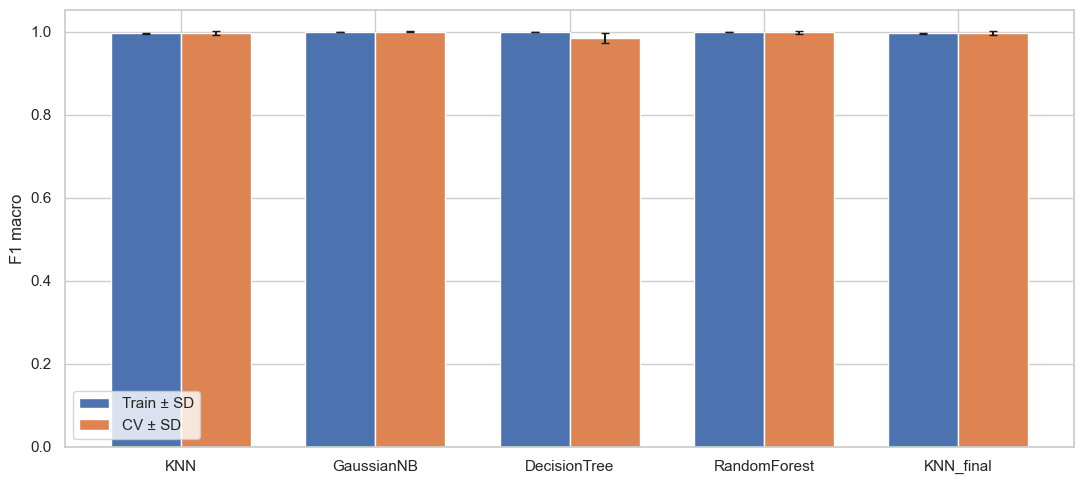

In [246]:
positions, width = np.arange(len(cv_summary)), 0.36
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(positions - width / 2, cv_summary['train_f1_macro'], width,
       yerr=cv_summary['train_f1_sd'], capsize=3, label='Train ± SD')
ax.bar(positions + width / 2, cv_summary['cv_f1_macro'], width,
       yerr=cv_summary['cv_f1_sd'], capsize=3, label='CV ± SD')
ax.set_xticks(positions, cv_summary['model'])
ax.set_ylabel('F1 macro')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'models_train_cv.png', dpi=150)
plt.show()


Gaussian NB là baseline. Đối chiếu KNN với các mô hình còn lại bằng cùng chỉ số và cùng fold. Test được dùng sau bước chốt này.

# Giai đoạn 4. Đánh giá và sử dụng mô hình

## 13. Đánh giá test

Test đã được xem ở các lần phát triển trước. Lần chạy mới cần tiếp tục ghi nhận lịch sử này khi diễn giải kết quả.

In [247]:
from sklearn.metrics import precision_score, recall_score

if (OUT / 'comparison.csv').exists() or (OUT / 'test_predictions.csv').exists():
    raise FileExistsError('Đã có kết quả test; dùng ô đọc lại bên dưới, không ghi đè.')
saved_selection = json.loads((OUT / 'selection.json').read_text(encoding='utf-8'))
if saved_selection != selection:
    raise ValueError('Cấu hình lựa chọn chưa khớp hồ sơ trước test.')


In [248]:
test_rows = []
predictions = X_test.copy()
predictions['true_label'] = y_test
for name in required_models:
    predicted = searches[name].best_estimator_.predict(X_test)
    predictions['pred_' + name] = predicted
    test_rows.append({'model': name, 'test_accuracy': accuracy_score(y_test, predicted),
        'test_f1_macro': f1_score(y_test, predicted, labels=classes, average='macro', zero_division=0),
        'test_precision_macro': precision_score(y_test, predicted, labels=classes, average='macro', zero_division=0),
        'test_recall_macro': recall_score(y_test, predicted, labels=classes, average='macro', zero_division=0)})
    report = classification_report(y_test, predicted, labels=classes, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT / f'{name}_classification_report.csv')


In [249]:
comparison = cv_summary.merge(pd.DataFrame(test_rows), on='model')
predictions.to_csv(OUT / 'test_predictions.csv')
comparison.to_csv(OUT / 'comparison.csv', index=False)
display(comparison.drop(columns='best_params'))


,model,vai_tro,train_f1_macro,train_f1_sd,cv_accuracy,cv_accuracy_sd,cv_f1_macro,cv_f1_sd,candidates,gap,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro
0,KNN,Mô hình chính,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,162,0.000384,0.997050,0.997596,0.997494,0.997807
1,GaussianNB,Baseline,0.999395,0.000303,0.999262,0.001476,0.999397,0.001207,3,-0.000002,0.997050,0.997596,0.997494,0.997807
2,DecisionTree,So sánh,1.000000,0.000000,0.991141,0.005993,0.984165,0.011647,6,0.015835,0.985251,0.947451,0.974503,0.955263
3,RandomForest,So sánh,1.000000,0.000000,0.999262,0.001476,0.998177,0.003645,4,0.001823,1.000000,1.000000,1.000000,1.000000
4,KNN_final,Biến thể KNN chọn bằng CV,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,4,0.000384,0.997050,0.997596,0.997494,0.997807


### Ma trận nhầm lẫn

In [250]:
comparison = pd.read_csv(OUT / 'comparison.csv')
predictions = pd.read_csv(OUT / 'test_predictions.csv', index_col=0)
display(comparison.drop(columns='best_params'))


,model,vai_tro,train_f1_macro,train_f1_sd,cv_accuracy,cv_accuracy_sd,cv_f1_macro,cv_f1_sd,candidates,gap,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro
0,KNN,Mô hình chính,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,162,0.000384,0.997050,0.997596,0.997494,0.997807
1,GaussianNB,Baseline,0.999395,0.000303,0.999262,0.001476,0.999397,0.001207,3,-0.000002,0.997050,0.997596,0.997494,0.997807
2,DecisionTree,So sánh,1.000000,0.000000,0.991141,0.005993,0.984165,0.011647,6,0.015835,0.985251,0.947451,0.974503,0.955263
3,RandomForest,So sánh,1.000000,0.000000,0.999262,0.001476,0.998177,0.003645,4,0.001823,1.000000,1.000000,1.000000,1.000000
4,KNN_final,Biến thể KNN chọn bằng CV,0.996041,0.001415,0.996307,0.003300,0.995656,0.004619,4,0.000384,0.997050,0.997596,0.997494,0.997807


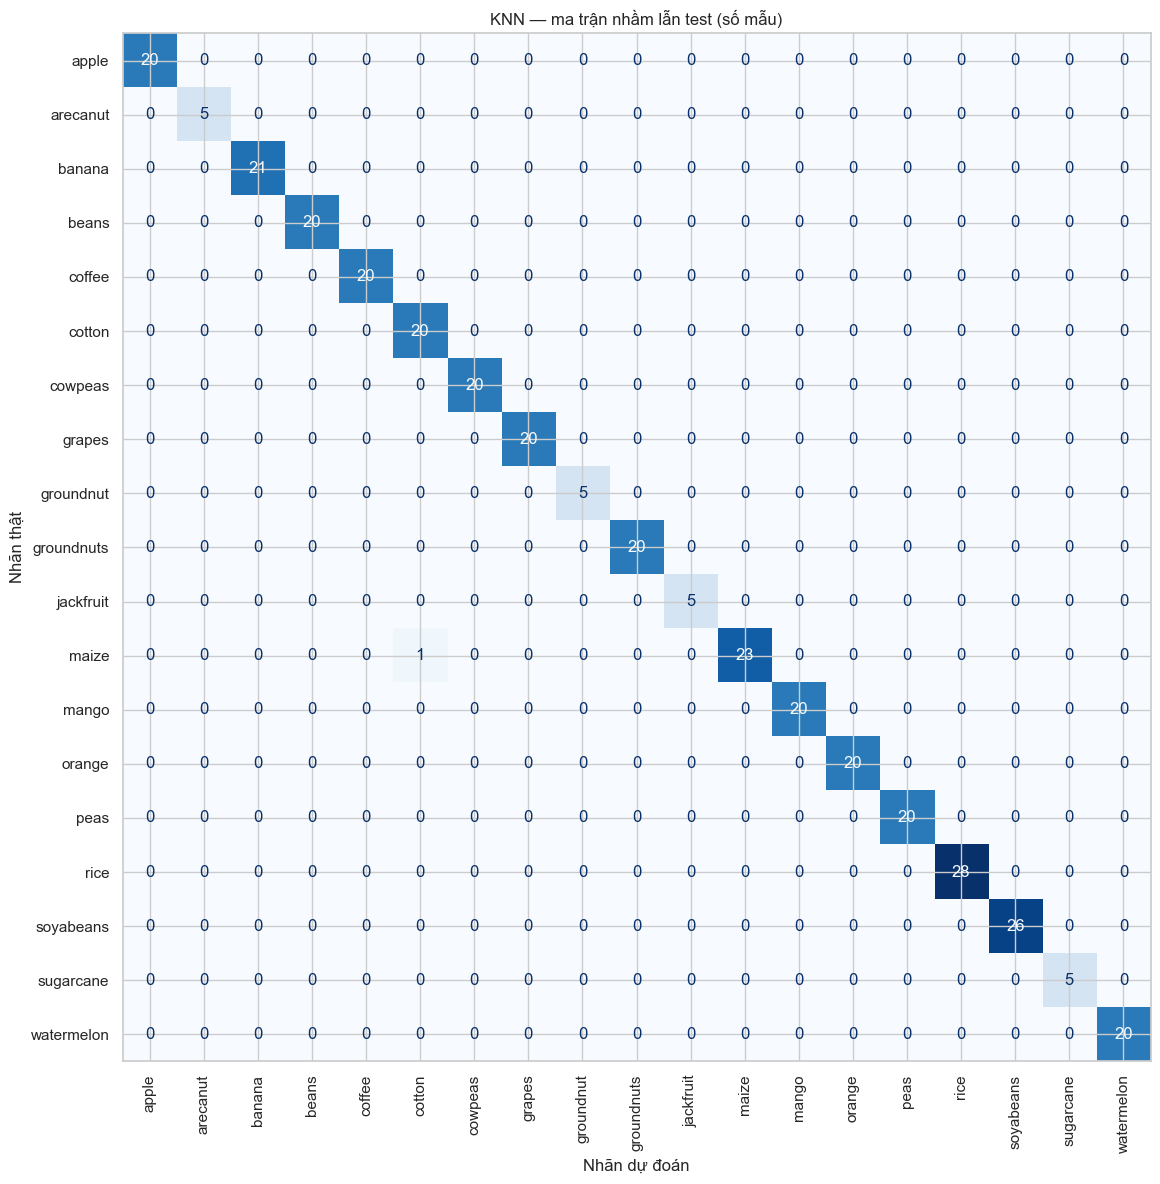

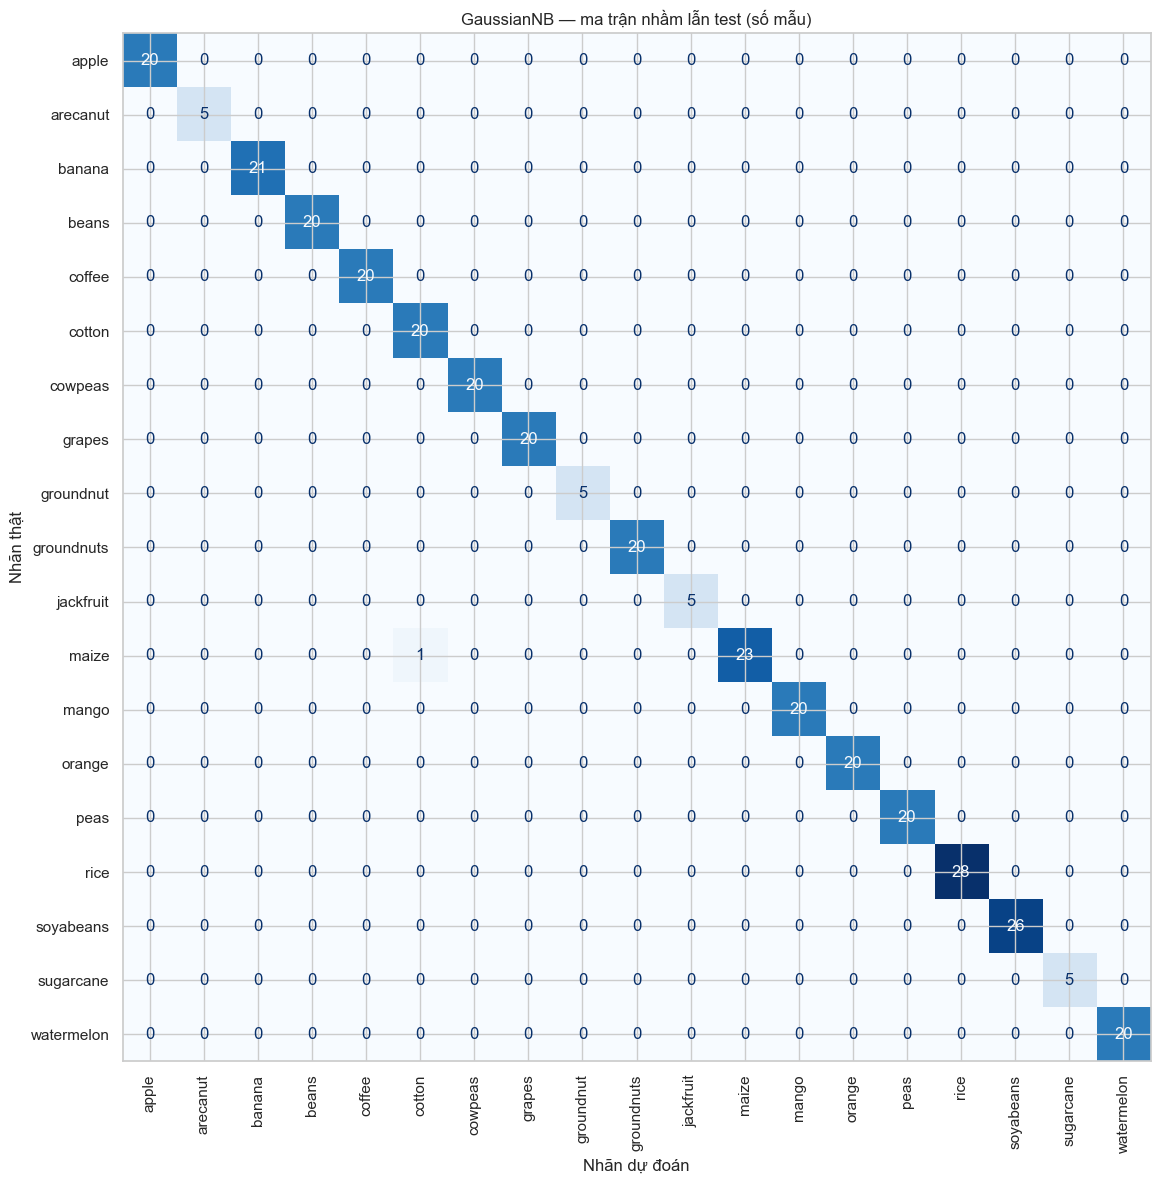

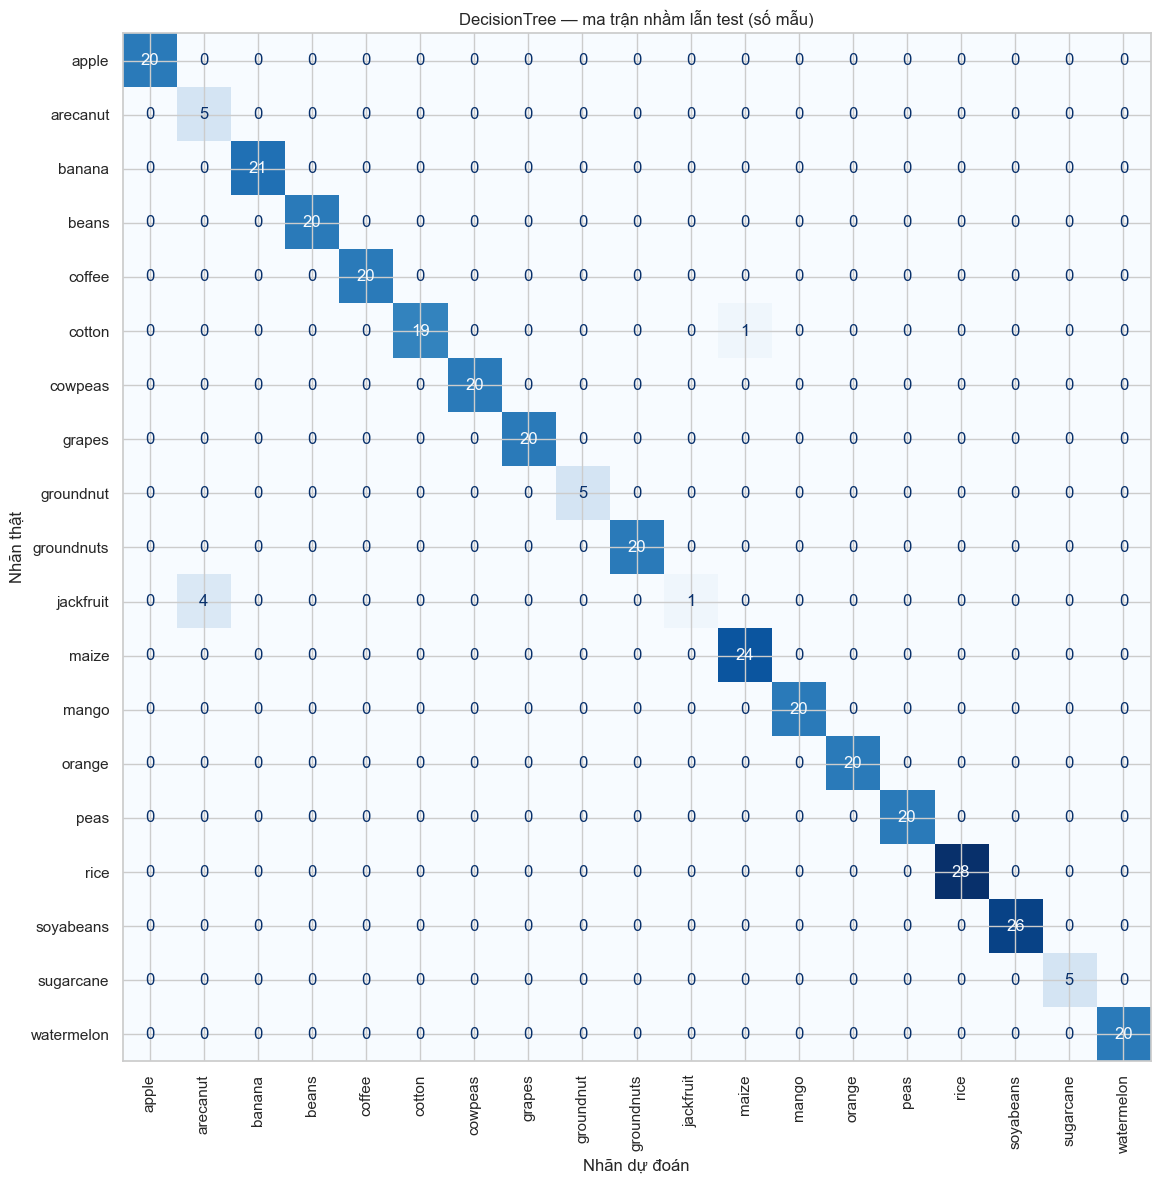

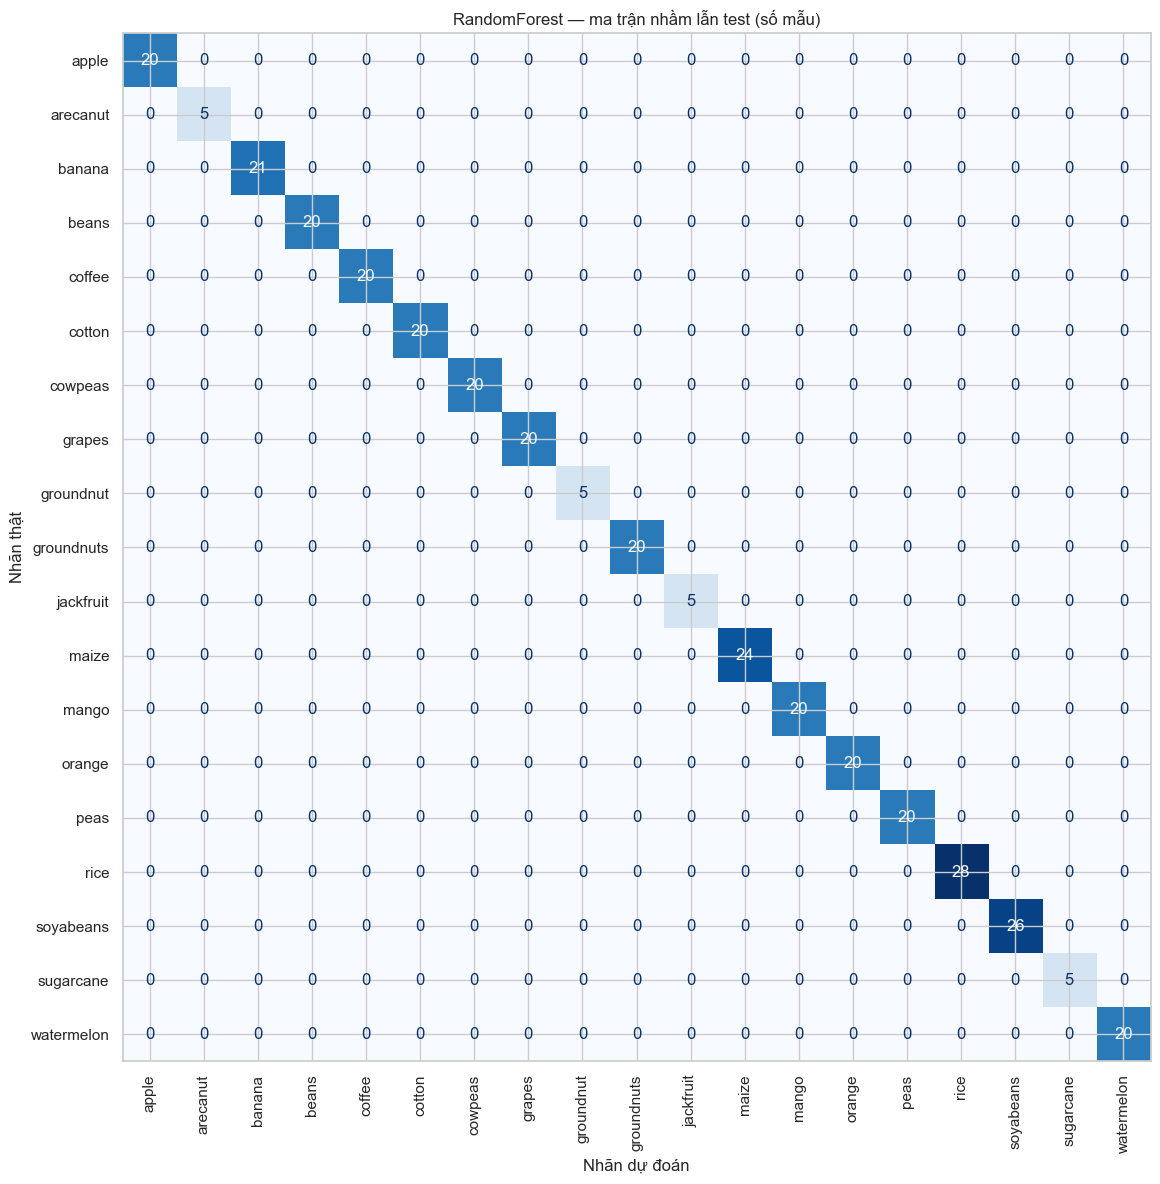

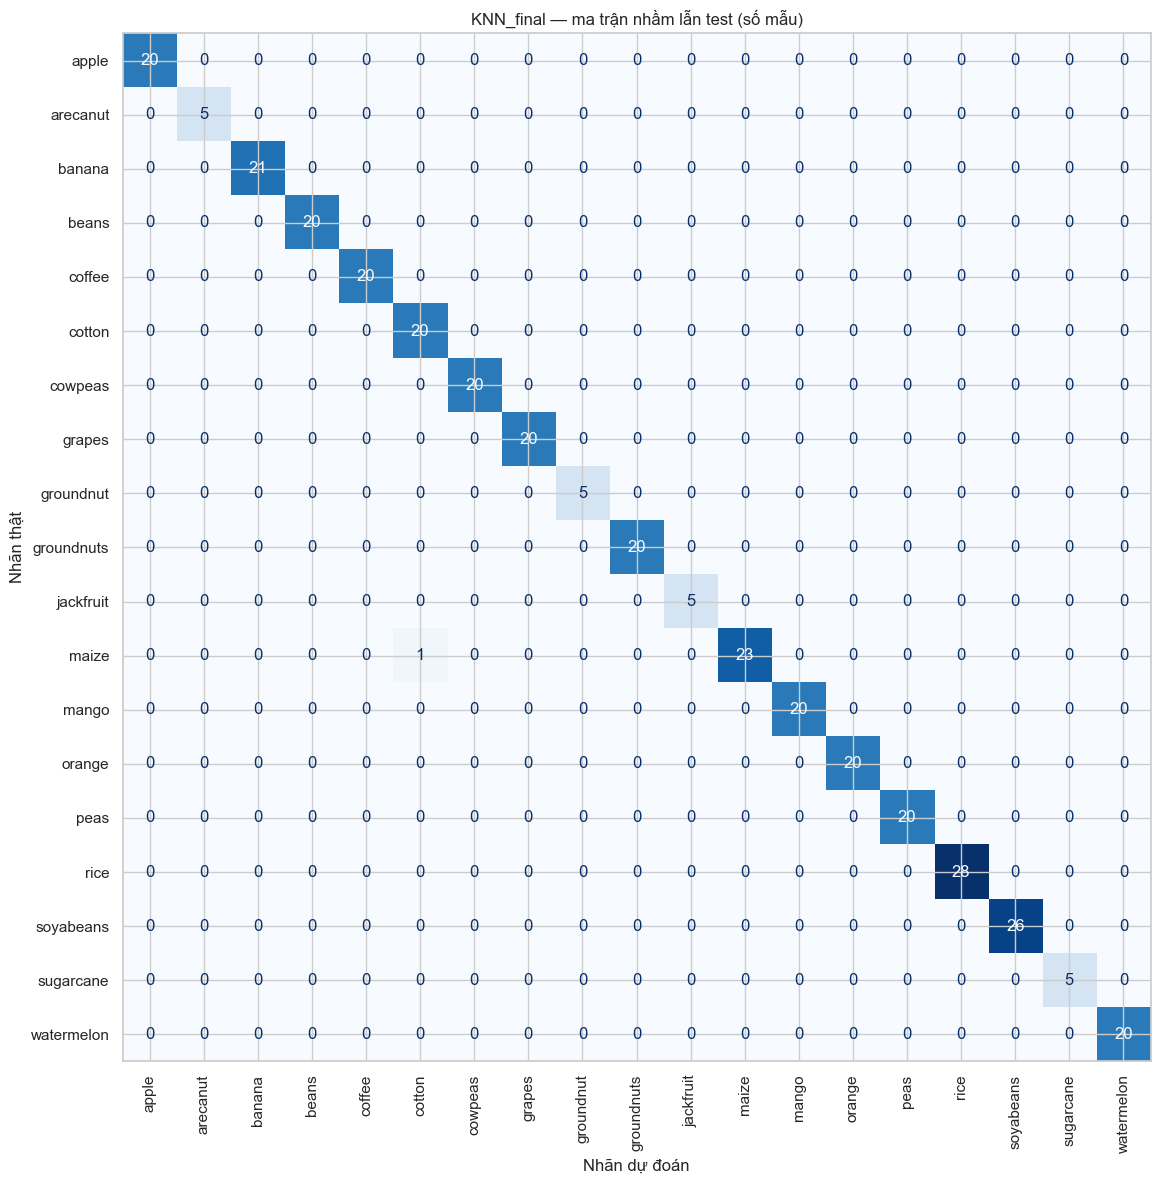

In [251]:
for name in required_models:
    fig, ax = plt.subplots(figsize=(13, 12))
    ConfusionMatrixDisplay.from_predictions(
        predictions['true_label'], predictions['pred_' + name], labels=classes,
        display_labels=classes, xticks_rotation=90, cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name + ' — ma trận nhầm lẫn test (số mẫu)')
    ax.set_xlabel('Nhãn dự đoán')
    ax.set_ylabel('Nhãn thật')
    fig.tight_layout()
    fig.savefig(OUT / f'{name}_confusion_matrix.png', dpi=150)
    plt.show()


Hàng là nhãn thật, cột là nhãn dự đoán. Xem các ô ngoài đường chéo cùng số mẫu của mỗi lớp.

## 14. Phân tích lỗi

### KNN được chọn từ lưới tham số

In [252]:
predictions['is_error'] = predictions['true_label'].ne(predictions['pred_KNN'])
error_by_crop = predictions.groupby('true_label')['is_error'].agg(so_mau='size', so_sai='sum')
error_by_crop = error_by_crop.reindex(classes, fill_value=0)
error_by_crop['ty_le_sai'] = error_by_crop['so_sai'].div(error_by_crop['so_mau'].replace(0, np.nan))
error_by_crop = error_by_crop.sort_values(['ty_le_sai', 'so_sai'], ascending=False)
errors = predictions.loc[predictions['is_error']].copy()
error_pairs = errors.groupby(['true_label', 'pred_KNN']).size().rename('so_mau').reset_index()


In [253]:
display(error_by_crop)
display(error_pairs.sort_values('so_mau', ascending=False).head(10))
display(errors[FEATURES + ['true_label', 'pred_KNN']].head(10))
print('Số mẫu KNN sai:', len(errors), '/', len(predictions))


,so_mau,so_sai,ty_le_sai
true_label,,,
maize,24,1,0.041667
apple,20,0,0.000000
arecanut,5,0,0.000000
banana,21,0,0.000000
beans,20,0,0.000000
coffee,20,0,0.000000
cotton,20,0,0.000000
cowpeas,20,0,0.000000
grapes,20,0,0.000000


,true_label,pred_KNN,so_mau
0,maize,cotton,1


,N,P,K,temperature,humidity,ph,rainfall,true_label,pred_KNN
sample_id,,,,,,,,,
140,99.0,56.0,17.0,24.108592,73.131123,6.23433,71.075622,maize,cotton


Số mẫu KNN sai: 1 / 339


In [254]:
error_by_crop.to_csv(OUT / 'knn_errors_by_crop.csv', encoding='utf-8-sig')
error_pairs.to_csv(OUT / 'knn_confused_pairs.csv', index=False, encoding='utf-8-sig')
errors.to_csv(OUT / 'knn_errors.csv')


### Biến thể KNN cuối

In [255]:
final_error_mask = predictions['true_label'].ne(predictions['pred_KNN_final'])
final_errors = predictions.loc[final_error_mask].copy()
final_error_pairs = final_errors.groupby(['true_label', 'pred_KNN_final']).size().rename('so_mau').reset_index()
final_by_crop = predictions.assign(is_final_error=final_error_mask).groupby('true_label')['is_final_error'].agg(so_mau='size', so_sai='sum')
final_by_crop['ty_le_sai'] = final_by_crop['so_sai'] / final_by_crop['so_mau']


In [256]:
display(final_by_crop.sort_values('ty_le_sai', ascending=False))
display(final_error_pairs.sort_values('so_mau', ascending=False).head(10))
display(final_errors[FEATURES + ['true_label', 'pred_KNN_final']].head(10))


,so_mau,so_sai,ty_le_sai
true_label,,,
maize,24,1,0.041667
arecanut,5,0,0.000000
apple,20,0,0.000000
banana,21,0,0.000000
beans,20,0,0.000000
cotton,20,0,0.000000
coffee,20,0,0.000000
grapes,20,0,0.000000
groundnut,5,0,0.000000


,true_label,pred_KNN_final,so_mau
0,maize,cotton,1


,N,P,K,temperature,humidity,ph,rainfall,true_label,pred_KNN_final
sample_id,,,,,,,,,
140,99.0,56.0,17.0,24.108592,73.131123,6.23433,71.075622,maize,cotton


In [257]:
final_errors.to_csv(OUT / 'knn_final_errors.csv')
final_by_crop.to_csv(OUT / 'knn_final_errors_by_crop.csv')
final_error_pairs.to_csv(OUT / 'knn_final_confused_pairs.csv', index=False)
print('Số mẫu KNN cuối sai:', len(final_errors), '/', len(predictions))


Số mẫu KNN cuối sai: 1 / 339


Các lớp ít mẫu cần được đọc cùng support. Ghi rõ những cặp nhãn dễ nhầm và các đặc trưng của mẫu sai.

## 15. Lưu Pipeline KNN

In [258]:
MODEL_PATH = OUT / 'knn_crop.joblib'
if not (OUT / 'comparison.csv').exists():
    raise FileNotFoundError('Hoàn thành đánh giá trước khi lưu bản demo.')
if MODEL_PATH.exists():
    raise FileExistsError('Mô hình đã lưu; nạp lại thay vì ghi đè.')


In [259]:
bundle = {
    'schema_version': 1, 'pipeline': searches['KNN_final'].best_estimator_,
    'features': FEATURES, 'classes': searches['KNN_final'].best_estimator_.classes_.tolist(),
    'training_bounds': {f: [float(X_train[f].min()), float(X_train[f].max())] for f in FEATURES},
    'config': config, 'selection': selection, 'versions': VERSIONS,
}
joblib.dump(bundle, MODEL_PATH)


['D:\\Crop-Recommendation-ML\\outputs\\crop_b_02\\knn_crop.joblib']

In [260]:
metadata = {key: value for key, value in bundle.items() if key != 'pipeline'}
(OUT / 'model_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT / 'python_runtime.json').write_text(json.dumps({'python': sys.version}), encoding='utf-8')
(OUT / 'inference-requirements.txt').write_text('\n'.join(f'{p}=={VERSIONS[p]}' for p in packages) + '\n', encoding='utf-8')
print('Đã lưu:', MODEL_PATH)


Đã lưu: D:\Crop-Recommendation-ML\outputs\crop_b_02\knn_crop.joblib


## 16. Nạp lại và kiểm tra dự đoán

In [261]:
loaded = joblib.load(OUT / 'knn_crop.joblib')
if loaded.get('schema_version') != 1 or loaded['features'] != FEATURES:
    raise ValueError('File không đúng cấu trúc hoặc thứ tự đặc trưng.')
assert list(loaded['pipeline'].classes_) == loaded['classes']


In [262]:
probe = X_train.iloc[:8]
original_prob = searches['KNN_final'].best_estimator_.predict_proba(probe)
loaded_prob = loaded['pipeline'].predict_proba(probe)
np.testing.assert_allclose(original_prob, loaded_prob, rtol=1e-12, atol=1e-12)
assert loaded_prob.shape == (len(probe), len(loaded['classes']))
np.testing.assert_allclose(loaded_prob.sum(axis=1), np.ones(len(probe)))
print('Đối chiếu lưu/nạp đạt khi ô chạy xong không có lỗi assertion.')


Đối chiếu lưu/nạp đạt khi ô chạy xong không có lỗi assertion.


In [263]:
def validate_sample(sample, features):
    if set(sample) != set(features):
        raise ValueError(f'Cần đúng các trường: {features}')
    if any(isinstance(sample[f], (bool, np.bool_)) for f in features):
        raise ValueError('Nhập số đo, không nhập True/False.')
    row = pd.DataFrame([{f: float(sample[f]) for f in features}])
    if not np.isfinite(row.to_numpy()).all():
        raise ValueError('Không nhận NaN hoặc vô cực.')
    if row[['N', 'P', 'K', 'rainfall']].lt(0).any().any():
        raise ValueError('N/P/K và rainfall không âm.')
    if not 0 <= row.at[0, 'humidity'] <= 100 or not 0 <= row.at[0, 'ph'] <= 14:
        raise ValueError('humidity thuộc [0,100], ph thuộc [0,14].')
    return row


In [264]:
def recommend_top3(model_bundle, sample):
    row = validate_sample(sample, model_bundle['features'])
    model = model_bundle['pipeline']
    probability = np.asarray(model.predict_proba(row)[0])
    if not np.isfinite(probability).all() or (probability < 0).any() or not np.isclose(probability.sum(), 1):
        raise ValueError('Xác suất mô hình không hợp lệ.')
    order = np.argsort(-probability, kind='stable')[:3]
    result = pd.DataFrame({'cay_trong': model.classes_[order], 'xac_suat': probability[order]})
    result['xac_suat_%'] = 100 * result['xac_suat']
    result['dien_giai'] = np.where(result['xac_suat'] > 0, 'Có phiếu', 'Không có phiếu; chưa đủ căn cứ')
    notes = ['Điểm phiếu KNN chưa hiệu chỉnh, không phải xác suất canh tác thành công.']
    for f, (low, high) in model_bundle['training_bounds'].items():
        if not low <= row.at[0, f] <= high:
            notes.append(f'{f} ngoài khoảng train [{low:g}, {high:g}].')
    if len(set(probability)) < len(probability) and any((probability == probability[i]).sum() > 1 for i in order):
        notes.append('Có đồng điểm; thứ tự giữa các nhãn cùng điểm không thể hiện ưu tiên.')
    return result, notes


In [265]:
sample = X_train.iloc[0].to_dict()
top3_check, _ = recommend_top3(loaded, dict(reversed(list(sample.items()))))
assert len(top3_check) == 3 and top3_check['xac_suat'].is_monotonic_decreasing
assert top3_check['xac_suat'].sum() <= 1 + 1e-12
bad_samples = [
    {f: v for f, v in sample.items() if f != 'N'},
    {**sample, 'ph': 20}, {**sample, 'temperature': float('nan')},
]
for bad in bad_samples:
    try:
        validate_sample(bad, FEATURES)
    except (ValueError, TypeError):
        pass
    else:
        raise AssertionError('Đầu vào sai chưa được chặn.')
print('Các trường hợp kiểm tra phần mềm đã qua nếu không có lỗi phía trên.')


Các trường hợp kiểm tra phần mềm đã qua nếu không có lỗi phía trên.


## 17. Demo top-3

Thay bảy giá trị trong `new_soil` để thử mẫu khác. Kết quả biểu diễn điểm phiếu KNN.

In [266]:
demo_bundle = joblib.load(OUT / 'knn_crop.joblib')
new_soil = {'N': 85, 'P': 40, 'K': 40, 'temperature': 26.0,
            'humidity': 80.0, 'ph': 6.5, 'rainfall': 200.0}


In [267]:
top3, notes = recommend_top3(demo_bundle, new_soil)
display(top3)
for note in notes:
    print('-', note)


,cay_trong,xac_suat,xac_suat_%,dien_giai
0,rice,1.0,100.0,Có phiếu
1,apple,0.0,0.0,Không có phiếu; chưa đủ căn cứ
2,arecanut,0.0,0.0,Không có phiếu; chưa đủ căn cứ


- Điểm phiếu KNN chưa hiệu chỉnh, không phải xác suất canh tác thành công.
- Có đồng điểm; thứ tự giữa các nhãn cùng điểm không thể hiện ưu tiên.


# Giai đoạn 5. Tổng hợp và lưu hồ sơ

## 18. Đối chiếu hai dataset

Sau A, bảng hiển thị A. Sau B, bảng đối chiếu hai lần chạy cùng mã `RUN_VERSION`.

In [268]:
RUNS = {
    'A': ROOT / 'outputs' / f'crop_a_{RUN_VERSION}',
    'B': ROOT / 'outputs' / f'crop_b_{RUN_VERSION}',
}
COMMON_MODELS = ['KNN', 'GaussianNB', 'DecisionTree', 'RandomForest']
PROTOCOL_KEYS = [
    'features', 'seed', 'test_size_groups', 'cv_folds',
    'k_values', 'group_decimals', 'versions',
]


In [269]:
def read_run(dataset_name, run_dir):
    required = ['config.json', 'split.json', 'comparison.csv', 'cv_summary.csv', 'dataset_used.csv']
    missing = [name for name in required if not (run_dir / name).is_file()]
    if missing:
        raise FileNotFoundError(f'{dataset_name} chưa đủ kết quả tại {run_dir}: {missing}')
    run_config = json.loads((run_dir / 'config.json').read_text(encoding='utf-8'))
    split = json.loads((run_dir / 'split.json').read_text(encoding='utf-8'))
    expected_mode = 'nguon_' + dataset_name.lower()
    if run_config['mode'] != expected_mode or split['mode'] != expected_mode:
        raise ValueError(f'Thư mục {run_dir} không phải thực nghiệm riêng {dataset_name}.')
    data_path = PATH_A if dataset_name == 'A' else PATH_B
    if run_config['sha_' + dataset_name.lower()] != sha256(data_path):
        raise ValueError(f'Dữ liệu {dataset_name} đã khác lần chạy được chọn.')
    table = pd.read_csv(run_dir / 'comparison.csv').set_index('model').loc[COMMON_MODELS].copy()
    saved_cv = pd.read_csv(run_dir / 'cv_summary.csv').set_index('model').loc[COMMON_MODELS]
    metric_columns = ['train_f1_macro', 'cv_accuracy', 'cv_accuracy_sd', 'cv_f1_macro', 'cv_f1_sd']
    pd.testing.assert_frame_equal(table[metric_columns], saved_cv[metric_columns])
    used = pd.read_csv(run_dir / 'dataset_used.csv')
    if set(used[TARGET]) != set(split['classes']):
        raise ValueError(f'Hệ nhãn {dataset_name} không khớp hồ sơ chia tập.')
    table['dataset'], table['so_mau'], table['so_lop'] = dataset_name, len(used), len(split['classes'])
    table['vai_tro'] = [MODEL_ROLES[name] for name in table.index]
    table['run_dir'] = str(run_dir.relative_to(ROOT))
    return table.reset_index(), run_config


In [270]:
tables, configs = {}, {}
required_files = ['config.json', 'split.json', 'comparison.csv', 'cv_summary.csv', 'dataset_used.csv']
for dataset_name, run_dir in RUNS.items():
    missing = [name for name in required_files if not (run_dir / name).is_file()]
    if missing:
        print(f'{dataset_name} chưa hoàn thành tại {run_dir}. Thiếu: {missing}')
        continue
    tables[dataset_name], configs[dataset_name] = read_run(dataset_name, run_dir)
if not tables:
    raise FileNotFoundError('Hoàn thành ít nhất một dataset đến mục 13 trước khi tổng hợp.')
if len(tables) == 2:
    for key in PROTOCOL_KEYS:
        if configs['A'][key] != configs['B'][key]:
            raise ValueError(f'Hai lần chạy khác điều kiện {key}; cần kiểm tra trước khi đối chiếu.')


In [271]:
if len(tables) == 2:
    for name in COMMON_MODELS:
        grids = [pd.read_csv(RUNS[key] / f'{name}_cv_raw.csv') for key in tables]
        param_columns = sorted(col for col in grids[0] if col.startswith('param_'))
        signatures = [set(map(tuple, grid[param_columns].fillna('<none>').astype(str).to_numpy()))
                      for grid in grids]
        if signatures[0] != signatures[1]:
            raise ValueError(f'Lưới tham số {name} của A và B khác nhau.')


In [272]:
two_datasets = pd.concat(tables.values(), ignore_index=True)
display(two_datasets[['dataset', 'so_mau', 'so_lop', 'model', 'vai_tro', 'run_dir']])


,dataset,so_mau,so_lop,model,vai_tro,run_dir
0,A,2200,22,KNN,Mô hình chính,outputs\crop_a_02
1,A,2200,22,GaussianNB,Baseline,outputs\crop_a_02
2,A,2200,22,DecisionTree,So sánh,outputs\crop_a_02
3,A,2200,22,RandomForest,So sánh,outputs\crop_a_02
4,B,1693,19,KNN,Mô hình chính,outputs\crop_b_02
5,B,1693,19,GaussianNB,Baseline,outputs\crop_b_02
6,B,1693,19,DecisionTree,So sánh,outputs\crop_b_02
7,B,1693,19,RandomForest,So sánh,outputs\crop_b_02


In [273]:
baseline_scores = two_datasets.loc[two_datasets['model'].eq('GaussianNB')].set_index('dataset')
two_datasets['chenh_cv_so_voi_nb'] = 100 * (
    two_datasets['cv_f1_macro'] - two_datasets['dataset'].map(baseline_scores['cv_f1_macro']))
two_datasets['chenh_test_so_voi_nb'] = 100 * (
    two_datasets['test_f1_macro'] - two_datasets['dataset'].map(baseline_scores['test_f1_macro']))


In [274]:
readable = two_datasets[['dataset', 'model', 'vai_tro']].copy()
for metric, sd, title in [('cv_accuracy', 'cv_accuracy_sd', 'CV Accuracy'),
                          ('cv_f1_macro', 'cv_f1_sd', 'CV F1 macro')]:
    readable[title] = [f'{mean:.4f} ± {spread:.4f}'
                       for mean, spread in zip(two_datasets[metric], two_datasets[sd])]
readable['Test Accuracy'] = two_datasets['test_accuracy'].round(4)
readable['Test F1 macro'] = two_datasets['test_f1_macro'].round(4)
readable['Chênh test với NB (điểm %)'] = two_datasets['chenh_test_so_voi_nb'].round(2)
display(readable)


,dataset,model,vai_tro,CV Accuracy,CV F1 macro,Test Accuracy,Test F1 macro,Chênh test với NB (điểm %)
0,A,KNN,Mô hình chính,0.9835 ± 0.0011,0.9837 ± 0.0011,0.9773,0.9771,-1.83
1,A,GaussianNB,Baseline,0.9938 ± 0.0045,0.9937 ± 0.0045,0.9955,0.9954,0.00
2,A,DecisionTree,So sánh,0.9875 ± 0.0069,0.9875 ± 0.0069,0.9795,0.9794,-1.60
3,A,RandomForest,So sánh,0.9943 ± 0.0051,0.9943 ± 0.0051,0.9932,0.9932,-0.23
4,B,KNN,Mô hình chính,0.9963 ± 0.0033,0.9957 ± 0.0046,0.9971,0.9976,0.00
5,B,GaussianNB,Baseline,0.9993 ± 0.0015,0.9994 ± 0.0012,0.9971,0.9976,0.00
6,B,DecisionTree,So sánh,0.9911 ± 0.0060,0.9842 ± 0.0116,0.9853,0.9475,-5.01
7,B,RandomForest,So sánh,0.9993 ± 0.0015,0.9982 ± 0.0036,1.0000,1.0000,0.24


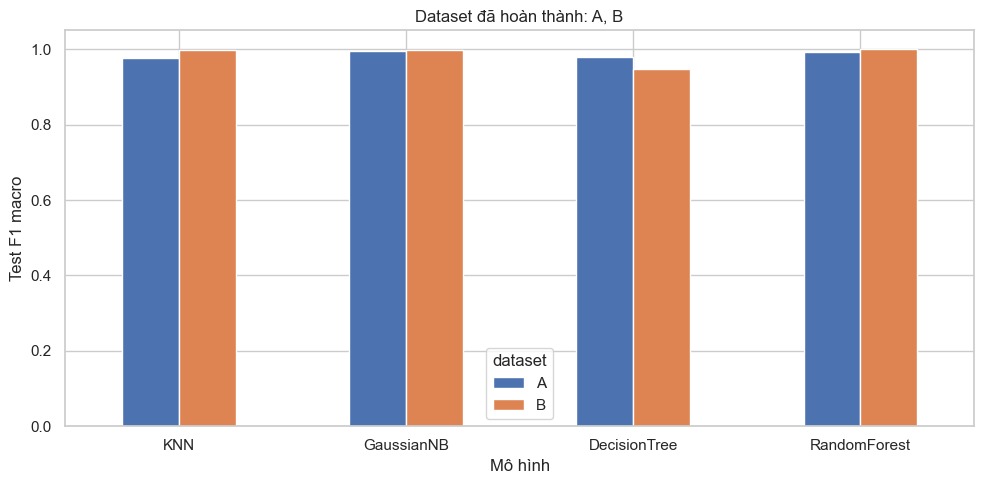

In [275]:
summary_name = 'doi_chieu_hai_dataset' if len(tables) == 2 else 'ket_qua_dataset_hien_co'
fig, ax = plt.subplots(figsize=(10, 5))
two_datasets.pivot(index='model', columns='dataset', values='test_f1_macro').loc[COMMON_MODELS].plot.bar(ax=ax)
ax.set_title('Dataset đã hoàn thành: ' + ', '.join(tables))
ax.set_ylabel('Test F1 macro')
ax.set_xlabel('Mô hình')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(OUT / f'{summary_name}.png', dpi=150)
plt.show()


In [276]:
summary_path = OUT / f'{summary_name}.csv'
if summary_path.exists():
    print('Đã có bảng tổng hợp:', summary_path)
else:
    two_datasets.to_csv(summary_path, index=False, encoding='utf-8-sig')
    print('Đã lưu bảng tổng hợp:', summary_path)


Đã lưu bảng tổng hợp: D:\Crop-Recommendation-ML\outputs\crop_b_02\doi_chieu_hai_dataset.csv


### Biến thể KNN cuối trên từng bộ

In [277]:
final_tables = []
for dataset_name in tables:
    result_table = pd.read_csv(RUNS[dataset_name] / 'comparison.csv')
    selected_row = result_table.loc[result_table['model'].eq('KNN_final')].copy()
    if selected_row.empty:
        print(dataset_name, 'chưa có kết quả KNN_final.')
    else:
        selected_row['dataset'] = dataset_name
        final_tables.append(selected_row)
if final_tables:
    final_two_datasets = pd.concat(final_tables, ignore_index=True)
    display(final_two_datasets[['dataset', 'model', 'cv_f1_macro', 'cv_f1_sd', 'test_accuracy', 'test_f1_macro']])


,dataset,model,cv_f1_macro,cv_f1_sd,test_accuracy,test_f1_macro
0,A,KNN_final,0.983660,0.001113,0.977273,0.977143
1,B,KNN_final,0.995656,0.004619,0.997050,0.997596


Hai bộ có hệ nhãn và mức chồng lặp khác nhau. Kết quả được trình bày riêng từng bộ, kèm giới hạn về nguồn dữ liệu.

## 19. Bảng kết quả dùng cho báo cáo

In [278]:
report_table = comparison[['model', 'vai_tro']].copy()
for metric, spread, name in [('cv_accuracy', 'cv_accuracy_sd', 'CV Accuracy'),
                              ('cv_f1_macro', 'cv_f1_sd', 'CV F1 macro')]:
    report_table[name] = [f'{mean:.4f} ± {sd:.4f}' for mean, sd in zip(comparison[metric], comparison[spread])]
report_table['Test Accuracy'] = comparison['test_accuracy'].round(4)
report_table['Test F1 macro'] = comparison['test_f1_macro'].round(4)
display(report_table)
report_table.to_csv(OUT / 'bang_mo_hinh_bao_cao.csv', index=False, encoding='utf-8-sig')


,model,vai_tro,CV Accuracy,CV F1 macro,Test Accuracy,Test F1 macro
0,KNN,Mô hình chính,0.9963 ± 0.0033,0.9957 ± 0.0046,0.9971,0.9976
1,GaussianNB,Baseline,0.9993 ± 0.0015,0.9994 ± 0.0012,0.9971,0.9976
2,DecisionTree,So sánh,0.9911 ± 0.0060,0.9842 ± 0.0116,0.9853,0.9475
3,RandomForest,So sánh,0.9993 ± 0.0015,0.9982 ± 0.0036,1.0000,1.0000
4,KNN_final,Biến thể KNN chọn bằng CV,0.9963 ± 0.0033,0.9957 ± 0.0046,0.9971,0.9976


## 20. Đóng gói thư mục kết quả

In [279]:
import shutil

archive_base = ROOT / f'crop_ml_{RUN_NAME}'
if archive_base.with_suffix('.zip').exists():
    raise FileExistsError('ZIP đã tồn tại; giữ bản cũ hoặc chọn tên sao lưu khác.')
archive = shutil.make_archive(str(archive_base), 'zip', root_dir=ROOT, base_dir=str(OUT.relative_to(ROOT)))
print('ZIP:', archive)


ZIP: D:\Crop-Recommendation-ML\crop_ml_crop_b_02.zip


## 21. Tài liệu tham khảo

- [Hai bộ dữ liệu và giấy phép kho GitHub](https://github.com/KRUTHIKTR/Crop-Recommendation-System-Using-Machine-Learning/tree/main/Datasets).
- [Mô tả Crop Recommendation trên Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset).
- [KNN](https://scikit-learn.org/1.7/modules/neighbors.html), [lựa chọn đặc trưng](https://scikit-learn.org/1.7/modules/feature_selection.html), [kiểm định và đánh giá](https://scikit-learn.org/1.7/model_selection.html).
- Tham khảo cách trình bày của `Crop recommendation final.ipynb`.

Có hỗ trợ biên tập mã bằng AI. Sinh viên tự chạy và kiểm tra kết quả.